# PREPROCESSING DATA HARGA SAHAM

In [5]:
import pandas as pd
# Menampilkan semua kolom, tanpa pemotongan
pd.set_option('display.max_columns', None) 

# Menampilkan semua baris
pd.set_option('display.max_rows', None) 

# Mengatur lebar tampilan agar tidak terpotong
pd.set_option('display.width', 1000) 

df_harga_mentah = pd.read_csv("GOTO_Historical_Data.csv")
print(df_harga_mentah.head())
print(df_harga_mentah.info())

                        Date   Open   High    Low  Close      Volume  Dividends  Stock Splits
0  2022-05-09 00:00:00+07:00  254.0  270.0  254.0  254.0   621345600        0.0           0.0
1  2022-05-10 00:00:00+07:00  254.0  254.0  238.0  238.0   201334400        0.0           0.0
2  2022-05-11 00:00:00+07:00  224.0  238.0  222.0  222.0  2942404500        0.0           0.0
3  2022-05-12 00:00:00+07:00  212.0  220.0  208.0  208.0   312982800        0.0           0.0
4  2022-05-13 00:00:00+07:00  200.0  200.0  194.0  194.0   407286800        0.0           0.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 911 entries, 0 to 910
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          911 non-null    object 
 1   Open          911 non-null    float64
 2   High          911 non-null    float64
 3   Low           911 non-null    float64
 4   Close         911 non-null    float64
 5   Volume        911 non-null

In [6]:
df_harga_mentah['Volume'] = df_harga_mentah['Volume'].astype(float)
df_harga_mentah['Date'] = pd.to_datetime(df_harga_mentah['Date'])
df_harga_mentah['Date'] = df_harga_mentah['Date'].dt.tz_localize(None).dt.normalize()
df_harga_mentah = df_harga_mentah.drop(columns=['Dividends', 'Stock Splits'])

tanggal_mulai = '2022-05-01'
tanggal_selesai = '2025-05-01'

# Membuat filter (mask) untuk rentang waktu
filter_waktu = (df_harga_mentah['Date'] >= tanggal_mulai) & (df_harga_mentah['Date'] <= tanggal_selesai)

# Menerapkan filter ke dataframe
df_harga_mentah = df_harga_mentah[filter_waktu]

df_harga_mentah = df_harga_mentah.reset_index(drop=True)


In [7]:
print(df_harga_mentah.info())
print(df_harga_mentah.head())
print(df_harga_mentah.tail())
print(df_harga_mentah.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 716 entries, 0 to 715
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    716 non-null    datetime64[ns]
 1   Open    716 non-null    float64       
 2   High    716 non-null    float64       
 3   Low     716 non-null    float64       
 4   Close   716 non-null    float64       
 5   Volume  716 non-null    float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 33.7 KB
None
        Date   Open   High    Low  Close        Volume
0 2022-05-09  254.0  270.0  254.0  254.0  6.213456e+08
1 2022-05-10  254.0  254.0  238.0  238.0  2.013344e+08
2 2022-05-11  224.0  238.0  222.0  222.0  2.942404e+09
3 2022-05-12  212.0  220.0  208.0  208.0  3.129828e+08
4 2022-05-13  200.0  200.0  194.0  194.0  4.072868e+08
          Date  Open  High   Low  Close        Volume
711 2025-04-24  80.0  82.0  79.0   80.0  2.750378e+09
712 2025-04-25  81.0  84.0  80.0   84.0  

In [8]:
# Pemeriksaan Data Kosong dan Bernilai 0
cek_missing = df_harga_mentah.isna().sum()
cek_0 = (df_harga_mentah == 0).sum()
print(cek_missing)
print(cek_0)
print(df_harga_mentah.shape)
df_0 = df_harga_mentah[df_harga_mentah.isna().any(axis=1) | (df_harga_mentah == 0).any(axis=1)]
print(df_0)

df_harga_mentah.loc[414, ['Open', 'High', 'Low', 'Close', 'Volume']] = [91, 92, 90, 92, 1514483800]
df_harga_mentah.loc[459, ['Open', 'High', 'Low', 'Close', 'Volume']] = [68, 69, 67, 69, 1659401900]
df_harga_mentah.loc[460, ['Open', 'High', 'Low', 'Close', 'Volume']] = [69, 71, 68, 70, 2963091300]

# Pemeriksaan Data Kosong dan Bernilai 0
cek_missing = df_harga_mentah.isna().sum()
cek_0 = (df_harga_mentah == 0).sum()
print(cek_missing)
print(cek_0)
print(df_harga_mentah.shape)
df_0 = df_harga_mentah[df_harga_mentah.isna().any(axis=1) | (df_harga_mentah == 0).any(axis=1)]
print(df_0)
print(df_harga_mentah.info())
cek = df_harga_mentah[df_harga_mentah['Date'] == '2024-01-15']
print(cek)

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Date      0
Open      0
High      0
Low       0
Close     0
Volume    3
dtype: int64
(716, 6)
          Date  Open  High   Low  Close  Volume
414 2024-01-15  91.0  91.0  91.0   91.0     0.0
459 2024-03-25  68.0  68.0  68.0   68.0     0.0
460 2024-03-26  68.0  68.0  68.0   68.0     0.0
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
(716, 6)
Empty DataFrame
Columns: [Date, Open, High, Low, Close, Volume]
Index: []
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 716 entries, 0 to 715
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    716 non-null    datetime64[ns]
 1   Open    716 non-null    float64       
 2   High    716 non-null    float64       
 3   Low     716 non-null    float64       
 4   Clo

# BUAT DATA WEB

In [14]:
df_web_mentah = pd.read_csv("data_berita_bersentimen_kontinu.csv")
df_harga_mentah['Date'] = pd.to_datetime(df_harga_mentah['Date'])
df_web_mentah['Date'] = pd.to_datetime(df_web_mentah['Date'])
df_web = pd.merge(df_harga_mentah, df_web_mentah[['Date', 'Nilai_Sentimen']], on='Date', how='left')
print(df_web_mentah.shape)
print(df_web.head())

df_web = df_web.dropna(subset=['Nilai_Sentimen'])
cek_missing = df_web.isna().sum()
cek_0 = (df_web == 0).sum()
print(cek_missing)
print(cek_0)
print(df_web.shape)

(715, 4)
        Date   Open   High    Low  Close        Volume  Nilai_Sentimen
0 2022-05-09  254.0  270.0  254.0  254.0  6.213456e+08             NaN
1 2022-05-10  254.0  254.0  238.0  238.0  2.013344e+08       -0.008215
2 2022-05-11  224.0  238.0  222.0  222.0  2.942404e+09       -0.023816
3 2022-05-12  212.0  220.0  208.0  208.0  3.129828e+08       -0.953367
4 2022-05-13  200.0  200.0  194.0  194.0  4.072868e+08       -0.613494
Date              0
Open              0
High              0
Low               0
Close             0
Volume            0
Nilai_Sentimen    0
dtype: int64
Date              0
Open              0
High              0
Low               0
Close             0
Volume            0
Nilai_Sentimen    0
dtype: int64
(715, 7)


In [16]:
df_web.to_csv("GOTO_Historical_Data_web.csv", index=False)

# TRANSFORMASI KE LOG RETURN

In [9]:
import pandas as pd
import numpy as np

# 1. Buat salinan dataframe agar data asli aman
df_log_return = df_harga_mentah.copy()

# 2. Ambil semua nama kolom KECUALI 'Date'
kolom_numerik = df_log_return.columns.drop('Date')

# 3. Lakukan perhitungan Log Return HANYA pada kolom numerik
# Rumus: ln(Nilai Hari Ini / Nilai Kemarin)
df_log_return[kolom_numerik] = np.log(df_log_return[kolom_numerik] / df_log_return[kolom_numerik].shift(1))

# 4. Hapus baris pertama karena perhitungannya pasti menghasilkan NaN (tidak ada data hari sebelumnya)
df_log_return.dropna(inplace=True)

# 5. (Opsional tapi disarankan) Reset index agar penomoran kembali rapi dimulai dari 0
df_log_return.reset_index(drop=True, inplace=True)

# Tampilkan hasilnya untuk memastikan kolom Date tetap ada dan index berupa angka
print(df_log_return.head())
print(df_log_return.info())
print(df_log_return.shape)

        Date      Open      High       Low     Close    Volume
0 2022-05-10  0.000000 -0.061088 -0.065064 -0.065064 -1.126920
1 2022-05-11 -0.125688 -0.065064 -0.069593 -0.069593  2.682015
2 2022-05-12 -0.055060 -0.078643 -0.065139 -0.065139 -2.240834
3 2022-05-13 -0.058269 -0.095310 -0.069680 -0.069680  0.263369
4 2022-05-17 -0.067209  0.113329 -0.069361  0.030459  2.198840
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 715 entries, 0 to 714
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    715 non-null    datetime64[ns]
 1   Open    715 non-null    float64       
 2   High    715 non-null    float64       
 3   Low     715 non-null    float64       
 4   Close   715 non-null    float64       
 5   Volume  715 non-null    float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 33.6 KB
None
(715, 6)


In [5]:
# Mencari nilai tertinggi (max)
x_max = df_log_return['Close'].max()

# Mencari nilai terendah (min)
x_min = df_log_return['Close'].min()

print(f"Nilai Tertinggi (xmax): {x_max}")
print(f"Nilai Terendah (xmin): {x_min}")

Nilai Tertinggi (xmax): 0.2990847045495925
Nilai Terendah (xmin): -0.22778393087071197


# Untuk df_y / Target

In [10]:
df_log_return.reset_index(drop=True, inplace=True)
df_y = df_log_return[['Date', 'Close']]
# Pemeriksaan Data Kosong
cek_missing = df_log_return.isna().sum()
print(cek_missing)
print(df_log_return.shape)
print(df_y.head())
print(df_y.info())

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64
(715, 6)
        Date     Close
0 2022-05-10 -0.065064
1 2022-05-11 -0.069593
2 2022-05-12 -0.065139
3 2022-05-13 -0.069680
4 2022-05-17  0.030459
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 715 entries, 0 to 714
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    715 non-null    datetime64[ns]
 1   Close   715 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 11.3 KB
None


# SPLITTING DATA

In [11]:
# Menentukan ukuran dataset
total_data = len(df_log_return)
total_data_y = len(df_y)

# Menentukan batas indeks untuk pembagian (80% Train, 10% Val, 10% Test)
train_end = int(total_data * 0.80)
val_end = int(total_data * 0.90) # 80% (train) + 10% (val) = 90%
train_end_y = int(total_data_y * 0.80)
val_end_y = int(total_data_y * 0.90)

# Melakukan slicing secara berurutan
df_train = df_log_return.iloc[:train_end].copy()
df_val = df_log_return.iloc[train_end:val_end].copy()
df_test = df_log_return.iloc[val_end:].copy() # Sisanya dari 90% hingga akhir menjadi Test (10%)
df_train_y = df_y.iloc[:train_end_y].copy()
df_val_y = df_y.iloc[train_end_y:val_end_y].copy()
df_test_y = df_y.iloc[val_end_y:].copy()

# (Opsional) Reset index agar setiap pecahan dataframe dimulai dari 0 lagi
df_train.reset_index(drop=True, inplace=True)
df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)
df_train_y.reset_index(drop=True, inplace=True)
df_val_y.reset_index(drop=True, inplace=True)
df_test_y.reset_index(drop=True, inplace=True)

# Mengecek hasil pembagian
print(f"Total data awal: {total_data} baris")
print(f"Jumlah data Train      (80%): {len(df_train)} baris")
print(f"Jumlah data Validation (10%): {len(df_val)} baris")
print(f"Jumlah data Test       (10%): {len(df_test)} baris")
print(f"Total data awal: {total_data_y} baris")
print(f"Jumlah data Train      (80%): {len(df_train_y)} baris")
print(f"Jumlah data Validation (10%): {len(df_val_y)} baris")
print(f"Jumlah data Test       (10%): {len(df_test_y)} baris")

# Mengecek tanggal awal dan akhir untuk memastikan urutannya benar
print("\nRentang Waktu Data Train:")
print(f"Awal: {df_train['Date'].iloc[0]} | Akhir: {df_train['Date'].iloc[-1]}")

print("\nRentang Waktu Data Validation:")
print(f"Awal: {df_val['Date'].iloc[0]} | Akhir: {df_val['Date'].iloc[-1]}")

print("\nRentang Waktu Data Test:")
print(f"Awal: {df_test['Date'].iloc[0]} | Akhir: {df_test['Date'].iloc[-1]}")

print("\nRentang Waktu Data Train:")
print(f"Awal: {df_train_y['Date'].iloc[0]} | Akhir: {df_train_y['Date'].iloc[-1]}")

print("\nRentang Waktu Data Validation:")
print(f"Awal: {df_val_y['Date'].iloc[0]} | Akhir: {df_val_y['Date'].iloc[-1]}")

print("\nRentang Waktu Data Test:")
print(f"Awal: {df_test_y['Date'].iloc[0]} | Akhir: {df_test_y['Date'].iloc[-1]}")

print("\nData Latih (5 Baris Pertama):")
print(df_train.head())

Total data awal: 715 baris
Jumlah data Train      (80%): 572 baris
Jumlah data Validation (10%): 71 baris
Jumlah data Test       (10%): 72 baris
Total data awal: 715 baris
Jumlah data Train      (80%): 572 baris
Jumlah data Validation (10%): 71 baris
Jumlah data Test       (10%): 72 baris

Rentang Waktu Data Train:
Awal: 2022-05-10 00:00:00 | Akhir: 2024-09-19 00:00:00

Rentang Waktu Data Validation:
Awal: 2024-09-20 00:00:00 | Akhir: 2025-01-03 00:00:00

Rentang Waktu Data Test:
Awal: 2025-01-06 00:00:00 | Akhir: 2025-04-30 00:00:00

Rentang Waktu Data Train:
Awal: 2022-05-10 00:00:00 | Akhir: 2024-09-19 00:00:00

Rentang Waktu Data Validation:
Awal: 2024-09-20 00:00:00 | Akhir: 2025-01-03 00:00:00

Rentang Waktu Data Test:
Awal: 2025-01-06 00:00:00 | Akhir: 2025-04-30 00:00:00

Data Latih (5 Baris Pertama):
        Date      Open      High       Low     Close    Volume
0 2022-05-10  0.000000 -0.061088 -0.065064 -0.065064 -1.126920
1 2022-05-11 -0.125688 -0.065064 -0.069593 -0.069593 

# NORMALISASI

# MINMAX SCALER

In [12]:
import pandas as pd
import joblib
from sklearn.preprocessing import MinMaxScaler

# 1. Buat salinan dataframe agar df_train dan df_test asli tetap aman
df_train_minmax = df_train.copy()
df_val_minmax = df_val.copy()
df_test_minmax = df_test.copy()
df_train_y_minmax = df_train_y.copy()
df_val_y_minmax = df_val_y.copy()
df_test_y_minmax = df_test_y.copy()

# 2. Ambil semua nama kolom KECUALI 'Date'
kolom_numerik = df_train.columns.drop('Date')
kolom_numerik_y = df_train_y.columns.drop('Date')

# 3. Inisialisasi MinMaxScaler
minmax_scaler_x = MinMaxScaler()
minmax_scaler_y = MinMaxScaler()

# 4. Lakukan FIT (pembelajaran) HANYA pada data TRAIN
minmax_scaler_x.fit(df_train_minmax[kolom_numerik])
minmax_scaler_y.fit(df_train_y_minmax[kolom_numerik_y])

# 5. Lakukan TRANSFORM pada data
df_train_minmax[kolom_numerik] = minmax_scaler_x.transform(df_train_minmax[kolom_numerik])
df_val_minmax[kolom_numerik] = minmax_scaler_x.transform(df_val_minmax[kolom_numerik])
df_test_minmax[kolom_numerik] = minmax_scaler_x.transform(df_test_minmax[kolom_numerik])
df_train_y_minmax[kolom_numerik_y] = minmax_scaler_y.transform(df_train_y_minmax[kolom_numerik_y])
df_val_y_minmax[kolom_numerik_y] = minmax_scaler_y.transform(df_val_y_minmax[kolom_numerik_y])
df_test_y_minmax[kolom_numerik_y] = minmax_scaler_y.transform(df_test_y_minmax[kolom_numerik_y])

# Cek hasil 5 baris pertama data Train
print("Hasil MinMaxScaler (Train):")
print(df_train_minmax.head())
print("Hasil MinMaxScaler y (Train):")
print(df_train_y_minmax.head())

# Cek hasil 5 baris pertama data Test
print("\nHasil MinMaxScaler (Test):")
print(df_test_minmax.head())

Hasil MinMaxScaler (Train):
        Date      Open      High       Low     Close    Volume
0 2022-05-10  0.506927  0.274419  0.321602  0.308844  0.256349
1 2022-05-11  0.238089  0.265757  0.310859  0.300247  0.756287
2 2022-05-12  0.389158  0.236170  0.321422  0.308701  0.110143
3 2022-05-13  0.382294  0.199856  0.310654  0.300082  0.438830
4 2022-05-17  0.363172  0.654434  0.311410  0.490147  0.692868
Hasil MinMaxScaler y (Train):
        Date     Close
0 2022-05-10  0.308844
1 2022-05-11  0.300247
2 2022-05-12  0.308701
3 2022-05-13  0.300082
4 2022-05-17  0.490147

Hasil MinMaxScaler (Test):
        Date      Open      High       Low     Close    Volume
0 2025-01-06  0.680448  0.568981  0.701940  0.480389  0.432890
1 2025-01-07  0.615250  0.355013  0.506506  0.432335  0.302475
2 2025-01-08  0.480356  0.407516  0.475905  0.432335  0.373623
3 2025-01-09  0.533498  0.380782  0.475905  0.432335  0.398361
4 2025-01-10  0.480356  0.460660  0.475905  0.455913  0.447949


In [8]:
joblib.dump(minmax_scaler_y, 'minmax_scaler_y.pkl')
joblib.dump(minmax_scaler_x, 'minmax_scaler_x.pkl')

['minmax_scaler_x.pkl']

# ROBUST SCALER

In [29]:
import pandas as pd
from sklearn.preprocessing import RobustScaler

# 1. Buat salinan dataframe agar df_train dan df_test asli tetap aman
df_train_robust = df_train.copy()
df_val_robust = df_val.copy()
df_test_robust = df_test.copy()
df_train_y_robust = df_train_y.copy()
df_val_y_robust = df_val_y.copy()
df_test_y_robust = df_test_y.copy()

# 2. Ambil semua nama kolom KECUALI 'Date'
kolom_numerik = df_train.columns.drop('Date')
kolom_numerik_y = df_train_y.columns.drop('Date')

# 3. Inisialisasi RobustScaler
robust_scaler_x = RobustScaler()
robust_scaler_y = RobustScaler()

# 4. Lakukan FIT (pembelajaran) HANYA pada data TRAIN
robust_scaler_x.fit(df_train_robust[kolom_numerik])
robust_scaler_y.fit(df_train_y_robust[kolom_numerik_y])

# 5. Lakukan TRANSFORM pada data TRAIN dan data TEST
df_train_robust[kolom_numerik] = robust_scaler_x.transform(df_train_robust[kolom_numerik])
df_val_robust[kolom_numerik] = robust_scaler_x.transform(df_val_robust[kolom_numerik])
df_test_robust[kolom_numerik] = robust_scaler_x.transform(df_test_robust[kolom_numerik])
df_train_y_robust[kolom_numerik_y] = robust_scaler_y.transform(df_train_y_robust[kolom_numerik_y])
df_val_y_robust[kolom_numerik_y] = robust_scaler_y.transform(df_val_y_robust[kolom_numerik_y])
df_test_y_robust[kolom_numerik_y] = robust_scaler_y.transform(df_test_y_robust[kolom_numerik_y])

# Cek hasil 5 baris pertama data Train
print("Hasil RobustScaler (Train):")
print(df_train_robust.head())
print("Hasil RobustScaler y (Train):")
print(df_train_y_robust.head())
# Cek hasil 5 baris pertama data Test
print("\nHasil RobustScaler (Test):")
print(df_test_robust.head())

Hasil RobustScaler (Train):
        Date      Open      High       Low     Close    Volume
0 2022-05-10  0.000000 -1.783838 -1.828860 -1.577548 -1.294641
1 2022-05-11 -3.055121 -1.899939 -1.956185 -1.687377  3.188347
2 2022-05-12 -1.338346 -2.296479 -1.830989 -1.579384 -2.605680
3 2022-05-13 -1.416351 -2.783177 -1.958620 -1.689477  0.341683
4 2022-05-17 -1.633653  3.309341 -1.949659  0.738522  2.619667
Hasil RobustScaler y (Train):
        Date     Close
0 2022-05-10 -1.577548
1 2022-05-11 -1.687377
2 2022-05-12 -1.579384
3 2022-05-13 -1.689477
4 2022-05-17  0.738522

Hasil RobustScaler (Test):
        Date      Open      High       Low     Close    Volume
0 2025-01-06  1.971930  2.164046  2.679056  0.613862  0.288422
1 2025-01-07  1.231004 -0.703679  0.362699  0.000000 -0.881024
2 2025-01-08 -0.301956  0.000000  0.000000  0.000000 -0.243037
3 2025-01-09  0.301956 -0.358302  0.000000  0.000000 -0.021206
4 2025-01-10 -0.301956  0.712261  0.000000  0.301200  0.423454


In [30]:
joblib.dump(robust_scaler_y, 'robust_scaler_y.pkl')
joblib.dump(robust_scaler_x, 'robust_scaler_x.pkl')

['robust_scaler_x.pkl']

# PREPROCESSING DATA BERITA

# READ DATA

In [2]:
import pandas as pd
df_berita_mentah = pd.read_csv("GOTO_Sentimen_Data.csv")
print(df_berita_mentah.head())
print(df_berita_mentah.tail())
print(df_berita_mentah.info())
print(df_berita_mentah.shape)

      Tanggal   Kategori                                              Judul  \
0  2026-02-26  Investasi  IHSG Dibuka Naik Tipis ke 8.324 Top Gainers LQ...   
1  2026-02-26  Investasi  Cek Rekomendasi Saham AADI ADRO AMRT BBNI dan ...   
2  2026-02-24  Investasi  IHSG Dibuka Naik ke 8.423 Top Gainers LQ45: JP...   
3  2026-02-12  Investasi  IHSG Melemah Simak Rekomendasi Teknikal Saham ...   
4  2026-02-09   Industri  GoTo Gandeng MRT Jakarta Hadirkan Blok M Hub G...   

                                                Link  
0  https://investasi.kontan.co.id/news/ihsg-dibuk...  
1  https://investasi.kontan.co.id/news/cek-rekome...  
2  https://investasi.kontan.co.id/news/ihsg-dibuk...  
3  https://investasi.kontan.co.id/news/ihsg-melem...  
4  https://industri.kontan.co.id/news/goto-ganden...  
         Tanggal      Kategori  \
2497  2022-03-16    Stocksetup   
2498  2022-03-16    Stocksetup   
2499  2022-03-16     Investasi   
2500  2022-03-15  Momsmoney.id   
2501  2022-03-15     Inve

# CBNC

In [2]:
import pandas as pd
df_berita_mentah = pd.read_csv("CBNC_Sentimen_Data.csv")
print(df_berita_mentah.head())
print(df_berita_mentah.tail())
print(df_berita_mentah.info())
print(df_berita_mentah.shape)

      Tanggal                                              Judul
0  2022-04-01  $100 million New Jersey deli owner Hometown In...
1  2022-04-02  A Ukrainian techie combined 'code and people' ...
2  2022-04-03  Nationalist Viktor Orban declares victory in H...
3  2022-04-04  Cramer's lightning round: I like Google over P...
4  2022-04-05  Inflation fears force Americans to rethink fin...
         Tanggal                                              Judul
1213  2025-07-27     Trump announces EU trade deal with 15% tariffs
1214  2025-07-28  Jim Cramer explains why Trump's trade deals di...
1215  2025-07-29  Bessent, Warsh, Hassett are the leading conten...
1216  2025-07-30  Microsoft's monster quarter and strong outlook...
1217  2025-07-31  Facing questions on AI strategy, Tim Cook says...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   Tanggal  1218 non

# Tipe DATA dan Filter Tanggal

In [ ]:
df_berita_mentah['Kategori'] = df_berita_mentah['Kategori'].astype('string')
df_berita_mentah['Judul'] = df_berita_mentah['Judul'].astype('string')
df_berita_mentah = df_berita_mentah.drop(columns=['Link'])
df_berita_mentah['Tanggal'] = pd.to_datetime(df_berita_mentah['Tanggal'])
df_berita_mentah['Tanggal'] = df_berita_mentah['Tanggal'].dt.tz_localize(None).dt.normalize()

tanggal_mulai = '2022-05-01'
tanggal_selesai = '2025-05-01'

# Membuat filter (mask) untuk rentang waktu
filter_waktu = (df_berita_mentah['Tanggal'] >= tanggal_mulai) & (df_berita_mentah['Tanggal'] <= tanggal_selesai)

# Menerapkan filter ke dataframe
df_berita_mentah = df_berita_mentah[filter_waktu]

df_berita_mentah = df_berita_mentah.reset_index(drop=True)

# CBNC

In [3]:
df_berita_mentah['Judul'] = df_berita_mentah['Judul'].astype('string')
df_berita_mentah['Tanggal'] = pd.to_datetime(df_berita_mentah['Tanggal'])
df_berita_mentah['Tanggal'] = df_berita_mentah['Tanggal'].dt.tz_localize(None).dt.normalize()

tanggal_mulai = '2022-05-01'
tanggal_selesai = '2025-05-01'

# Membuat filter (mask) untuk rentang waktu
filter_waktu = (df_berita_mentah['Tanggal'] >= tanggal_mulai) & (df_berita_mentah['Tanggal'] <= tanggal_selesai)

# Menerapkan filter ke dataframe
df_berita_mentah = df_berita_mentah[filter_waktu]

df_berita_mentah = df_berita_mentah.reset_index(drop=True)

In [34]:
print(df_berita_mentah.head())
print(df_berita_mentah.tail())
print(df_berita_mentah.info())
print(df_berita_mentah.shape)

     Tanggal   Kategori                                              Judul
0 2025-05-01  Investasi  Simak Rekomendasi Teknikal Saham BMRI AKRA dan...
1 2025-05-01  Investasi  Cermati Rekomendasi Saham GOTO di Tengah EBITA...
2 2025-05-01  Investasi  Raup Pendapatan Bersih Rp 139 Triliun Cek Sumb...
3 2025-05-01    Insight  GOTO Menutup April 2025 dengan Manis Saham Mel...
4 2025-04-30  Pusatdata  GOTO dan BRMS Jadi Top Leaders Saham PTRO Jadi...
        Tanggal   Kategori                                              Judul
2012 2022-05-10  Investasi  Saham Gojek Tokopedia (GOTO) dan Bukalapak (BU...
2013 2022-05-09  Investasi  Kompak Harga Saham BBRI & GOTO Anjlok di Perda...
2014 2022-05-09  Investasi  Cermati Rekomendasi Saham ADRO GOTO TLKM dan M...
2015 2022-05-05  Investasi  Market Cap GOTO ambles Rp 783 triliun sejak IP...
2016 2022-05-04  Investasi  Baru Melantai April Lalu Saham Gojek Tokopedia...
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2017 entries, 0 to 2016
Data col

# Hapus Duplikat dan Spasi

In [4]:
import re

# 3. Menghapus duplikat berdasarkan 'Tanggal_Harian'
# keep='last' akan mempertahankan baris terakhir yang muncul di setiap tanggal
df_berita_harian = df_berita_mentah.drop_duplicates(subset=['Tanggal'], keep='last').copy()

# 4. Merapikan dataframe (Opsional)
df_berita_harian = df_berita_harian.reset_index(drop=True)

def clean_financial_text(text):
       # 4. Merapikan spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Terapkan ke dataframe kamu
df_berita_harian['Judul'] = df_berita_harian['Judul'].apply(clean_financial_text)
# Tampilkan hasil
print(df_berita_harian)

        Tanggal                                              Judul
0    2022-05-01  Detroit automakers aren't letting up on a long...
1    2022-05-02  Cramer's lightning round: I like Magna over Te...
2    2022-05-03  Chipmaker AMD posts amazing quarter, gains sha...
3    2022-05-04  Consumers at breaking point as Fed's inflation...
4    2022-05-05  U.S. intel helped Ukraine sink Russian flagshi...
...         ...                                                ...
1092 2025-04-27  Elon Musk's xAI Holdings in talks to raise $20...
1093 2025-04-28  Domino's Pizza CEO unpacks earnings after mixe...
1094 2025-04-29  Jim Cramer says politicians should not forget ...
1095 2025-04-30  Despite Starbucks' earnings miss, Jim Cramer s...
1096 2025-05-01  Hasbro CEO details tariff impact: 'We're makin...

[1097 rows x 2 columns]


# Urutan Data dan Cek gabung

In [13]:
# 2. Urutkan kedua dataframe agar sama-sama dari 2022 ke 2025 (Ascending)
df_saham = df_log_return.sort_values(by='Date', ascending=True).reset_index(drop=True)
df_berita = df_berita_harian.sort_values(by='Tanggal', ascending=True).reset_index(drop=True)

# 3. Lakukan Left Join
# Dataframe saham menjadi patokan (left). Jika di tanggal tersebut tidak ada di df_berita,
# maka kolom berita (seperti 'Judul') akan diisi dengan NaN (kosong).
df_gabung_mentah = pd.merge(df_saham, df_berita, left_on='Date', right_on='Tanggal', how='left')

# 4. Deteksi hari saham buka yang TIDAK ADA beritanya
# Kita filter baris di mana kolom 'Judul' bernilai NaN (kosong)
df_tanpa_berita = df_gabung_mentah[df_gabung_mentah['Judul'].isna()].copy()

# Tampilkan informasi
print(f"Total hari bursa beroperasi: {len(df_saham)} hari")
print(f"Total hari bursa TANPA data berita: {len(df_tanpa_berita)} hari")
print(f"Persentase kekosongan data: {(len(df_tanpa_berita) / len(df_saham)) * 100:.2f}%\n")

print("Daftar tanggal bursa tanpa berita:")
# Menampilkan 10 tanggal teratas yang kosong beritanya
print(df_tanpa_berita[['Date']])

Total hari bursa beroperasi: 715 hari
Total hari bursa TANPA data berita: 0 hari
Persentase kekosongan data: 0.00%

Daftar tanggal bursa tanpa berita:
Empty DataFrame
Columns: [Date]
Index: []


In [17]:
print(df_berita.head())
print(df_berita.shape)
print(df_berita.info())
df_berita.to_csv("data_berita_cbnc.csv", index=False)

     Tanggal                                              Judul
0 2022-05-01  Detroit automakers aren't letting up on a long...
1 2022-05-02  Cramer's lightning round: I like Magna over Te...
2 2022-05-03  Chipmaker AMD posts amazing quarter, gains sha...
3 2022-05-04  Consumers at breaking point as Fed's inflation...
4 2022-05-05  U.S. intel helped Ukraine sink Russian flagshi...
(1097, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1097 entries, 0 to 1096
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Tanggal  1097 non-null   datetime64[ns]
 1   Judul    1097 non-null   object        
dtypes: datetime64[ns](1), object(1)
memory usage: 17.3+ KB
None


# CEK GABUNG TERJEMAH

In [83]:
df_terjemah3 = pd.read_csv("data_berita_terjemahan.csv")
df_saham3 = df_log_return.copy()
df_gabung_mentah3 = pd.concat([df_saham3.reset_index(drop=True), df_terjemah3.reset_index(drop=True)], axis=1)

# 4. Deteksi hari saham buka yang TIDAK ADA beritanya
# Kita filter baris di mana kolom 'Judul' bernilai NaN (kosong)
df_tanpa_berita3 = df_gabung_mentah3[df_gabung_mentah3['Judul'].isna()].copy()

# Tampilkan informasi
print(f"Total hari bursa beroperasi: {len(df_saham3)} hari")
print(f"Total hari bursa TANPA data berita: {len(df_tanpa_berita3)} hari")
print(f"Persentase kekosongan data: {(len(df_tanpa_berita3) / len(df_saham3)) * 100:.2f}%\n")

print("Daftar tanggal bursa tanpa berita:")
# Menampilkan 10 tanggal teratas yang kosong beritanya
cek_missing3 = df_gabung_mentah3.isna().sum()
print(cek_missing3)
print(df_gabung_mentah3)


Total hari bursa beroperasi: 715 hari
Total hari bursa TANPA data berita: 0 hari
Persentase kekosongan data: 0.00%

Daftar tanggal bursa tanpa berita:
Date             0
Open             0
High             0
Low              0
Close            0
Volume           0
Judul            0
Judul_English    0
dtype: int64
          Date      Open      High       Low     Close    Volume                                              Judul                                      Judul_English
0   2022-05-10  0.000000 -0.061088 -0.065064 -0.065064 -1.126920  Saham Gojek Tokopedia (GOTO) dan Bukalapak (BU...  Gojek Tokopedia (GOTO) and Bukalapak (BUKA) sh...
1   2022-05-11 -0.125688 -0.065064 -0.069593 -0.069593  2.682015  Berikut Rekomendasi Saham Samuel Sekuritas unt...  Following are Samuel Sekuritas' stock recommen...
2   2022-05-12 -0.055060 -0.078643 -0.065139 -0.065139 -2.240834  Harga Saham BBCA & GOTO Melemah di Perdagangan...  BBCA & GOTO Share Prices Weaken in Stock Excha...
3   2022-05-13 -

# TANGGAL BERITA

In [14]:
df_berita_khusus = df_gabung_mentah[['Judul']].dropna().copy()
df_berita_khusus = df_berita_khusus.reset_index(drop=True)
df_berita_khusus_date = df_gabung_mentah[['Date', 'Judul']].dropna().copy()

# Cek hasilnya
print(f"Jumlah baris berita yang siap diproses: {len(df_berita_khusus)}")
print(df_berita_khusus.head())
print(df_berita_khusus_date.head())
print(df_berita_khusus_date.shape)

Jumlah baris berita yang siap diproses: 715
                                               Judul
0           Cramer's lightning round: AECOM is a buy
1  As the U.S. dollar trades at a 20-year high, B...
2  The stocks of several electric vehicle compani...
3  Cryptocurrency luna crashes to $0 as UST falls...
4  Goldman Sachs reveals how to trade the 'troubl...
        Date                                              Judul
0 2022-05-10           Cramer's lightning round: AECOM is a buy
1 2022-05-11  As the U.S. dollar trades at a 20-year high, B...
2 2022-05-12  The stocks of several electric vehicle compani...
3 2022-05-13  Cryptocurrency luna crashes to $0 as UST falls...
4 2022-05-17  Goldman Sachs reveals how to trade the 'troubl...
(715, 2)


# TRANSLATE INGGRIS

In [81]:
# Pastikan kamu sudah menginstal library ini di terminal/command prompt:
# pip install deep-translator tqdm pandas

import pandas as pd
from deep_translator import GoogleTranslator
from tqdm import tqdm
import time

# 1. Inisialisasi Translator (Dari Indonesia 'id' ke Inggris 'en')
translator = GoogleTranslator(source='id', target='en')

# 2. Buat fungsi terjemahan yang kebal terhadap error (Robust Function)
def terjemahkan_aman(teks):
    try:
        # Pengecekan jika teks kosong atau bukan string
        if not isinstance(teks, str) or teks.strip() == "":
            return teks
        
        # Proses terjemahan
        hasil = translator.translate(teks)
        
        # Jeda sangat singkat (0.1 detik) agar server Google tidak memblokir IP kita (opsional tapi sangat disarankan)
        time.sleep(0.1) 
        
        return hasil
    except Exception as e:
        # Jika koneksi putus atau ada error, program tidak akan crash
        # Melainkan mengembalikan teks aslinya dan mencetak error
        print(f"Gagal menerjemahkan: '{teks}'. Error: {e}")
        return teks

# 3. Aktifkan progress bar untuk Pandas
tqdm.pandas(desc="Menerjemahkan Berita")

# 4. Terapkan fungsi ke kolom Judul dan simpan di kolom baru 'Judul_English'
# Menggunakan progress_apply alih-alih apply biasa agar muncul bar loading
df_berita_khusus['Judul_English'] = df_berita_khusus['Judul'].progress_apply(terjemahkan_aman)

# 5. SANGAT PENTING: Langsung simpan hasilnya ke CSV agar tidak hilang jika laptop mati!
df_berita_khusus.to_csv('data_berita_terjemahan.csv', index=False)

# Cek 5 data teratas untuk memastikan
print("\nProses Selesai! Berikut cuplikan datanya:")
print(df_berita_khusus[['Judul', 'Judul_English']].head())

Menerjemahkan Berita:   6%|▋         | 39/613 [03:26<1:12:54,  7.62s/it]

Gagal menerjemahkan: 'Keuntungan Telkom (TLKM) Investasi di GoTo Gojek Tokopedia (GOTO)'. Error: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))


Menerjemahkan Berita:  16%|█▌        | 99/613 [08:20<1:02:38,  7.31s/it]

Gagal menerjemahkan: 'IPO Blibli (BELI) Bakal Lebih Menarik dari IPO BUKA dan GOTO?'. Error: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))


Menerjemahkan Berita:  18%|█▊        | 111/613 [09:14<58:13,  6.96s/it] 

...

Gagal menerjemahkan: 'Saham Gojek Tokopedia (GOTO) Merosot Tajam Cermati Rekomendasi Analis'. Error: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))


Menerjemahkan Berita:  79%|███████▉  | 483/613 [40:49<1:02:40, 28.93s/it]

Gagal menerjemahkan: 'IHSG Naik di Awal Perdagangan Rabu (14/8) Saham GOTO Memimpin LQ45'. Error: ('Connection aborted.', RemoteDisconnected('Remote end closed connection without response'))


Menerjemahkan Berita: 100%|██████████| 613/613 [51:42<00:00,  5.06s/it]  



Proses Selesai! Berikut cuplikan datanya:
                                                                                Judul                                                              Judul_English
0                   Saham Gojek Tokopedia (GOTO) dan Bukalapak (BUKA) Kompak Kena ARB      Gojek Tokopedia (GOTO) and Bukalapak (BUKA) shares are subject to ARB
1                    Berikut Rekomendasi Saham Samuel Sekuritas untuk Hari Ini (11/5)     Following are Samuel Sekuritas' stock recommendations for today (11/5)
2                   Harga Saham BBCA & GOTO Melemah di Perdagangan Bursa Kamis (12/5)  BBCA & GOTO Share Prices Weaken in Stock Exchange Trading Thursday (12/5)
3  Harga Saham GOTO Anjlok Lagi Konsensus Menunjukkan Masih Ada Potensi Untuk Mendaki      GOTO Share Price Falls Again Consensus Shows Still Potential to Climb
4                                               Investasi Telkom di GOTO Masih Merugi                             Telkom's investment in GOTO is still a

# IMPORT DATA TERJEMAHAN

pip install transformers torch pandas tqdm

In [ ]:
import pandas as pd

pd.set_option('display.max_colwidth', 80) 
pd.set_option('display.max_columns', None)

df_berita = pd.read_csv('data_berita_terjemahan.csv')
df_berita.insert(0, 'Date', df_berita_khusus_date['Date'])

print(df_berita.shape)
print(df_berita.columns.tolist())
print(df_berita.head())  

cek_missing = df_berita.isna().sum()
cek_0 = (df_berita == 0).sum()
print(cek_missing)
print(cek_0)

(715, 3)
['Date', 'Judul', 'Judul_English']
        Date                                                                            Judul                                                              Judul_English
0 2022-05-10                Saham Gojek Tokopedia (GOTO) dan Bukalapak (BUKA) Kompak Kena ARB      Gojek Tokopedia (GOTO) and Bukalapak (BUKA) shares are subject to ARB
1 2022-05-11                 Berikut Rekomendasi Saham Samuel Sekuritas untuk Hari Ini (11/5)     Following are Samuel Sekuritas' stock recommendations for today (11/5)
2 2022-05-12                Harga Saham BBCA & GOTO Melemah di Perdagangan Bursa Kamis (12/5)  BBCA & GOTO Share Prices Weaken in Stock Exchange Trading Thursday (12/5)
3 2022-05-13  Harga Saham GOTO Anjlok Lagi Konsensus Menunjukkan Masih Ada Potensi Untuk M...      GOTO Share Price Falls Again Consensus Shows Still Potential to Climb
4 2022-05-17                                            Investasi Telkom di GOTO Masih Merugi                  

# CBNC

In [18]:
import pandas as pd

pd.set_option('display.max_colwidth', 80) 
pd.set_option('display.max_columns', None)

df_berita = pd.read_csv('data_berita_cbnc.csv')
df_berita = df_berita.rename(columns={'Tanggal': 'Date'})

print(df_berita.shape)
print(df_berita.columns.tolist())
print(df_berita.head())  

cek_missing = df_berita.isna().sum()
cek_0 = (df_berita == 0).sum()
print(cek_missing)
print(cek_0)

(1097, 2)
['Date', 'Judul']
         Date                                                                            Judul
0  2022-05-01  Detroit automakers aren't letting up on a long-standing rivalry, even as the...
1  2022-05-02                              Cramer's lightning round: I like Magna over Tenneco
2  2022-05-03  Chipmaker AMD posts amazing quarter, gains share despite supply chain challe...
3  2022-05-04  Consumers at breaking point as Fed's inflation battle heats up, investor Pet...
4  2022-05-05            U.S. intel helped Ukraine sink Russian flagship Moskva, officials say
Date     0
Judul    0
dtype: int64
Date     0
Judul    0
dtype: int64


# ANALISIS SENTIMEN FINBERT

In [21]:
import pandas as pd
from transformers import pipeline
from tqdm import tqdm

# 1. Load data hasil terjemahan
df_berita = pd.read_csv('data_berita_cbnc.csv')
df_berita = df_berita.rename(columns={'Tanggal': 'Date'})
df_berita = df_berita.rename(columns={'Judul': 'Judul_English'})
# df_berita = df_berita.copy() # Jika kamu sudah menjalankan kode sebelumnya, kamu bisa langsung pakai dataframe yang sudah ada tanpa perlu load ulang dari CSV. --- IGNORE ---


# 2. Inisialisasi model FinBERT dengan top_k=None agar mengeluarkan KETIGA probabilitas
print("Sedang memuat model FinBERT...")
finbert = pipeline("sentiment-analysis", model="ProsusAI/finbert", tokenizer="ProsusAI/finbert", top_k=None)

# 3. Fungsi dengan perhitungan matematis yang kamu pelajari
def hitung_skor_kontinu(teks):
    try:
        if not isinstance(teks, str) or teks.strip() == "":
            return 0.0 # Kembali ke nilai tengah (Netral) jika kosong
        
        # Hasil sekarang berupa list berisi 3 dictionary
        # Contoh: [{'label': 'positive', 'score': 0.8}, {'label': 'negative', 'score': 0.1}, {'label': 'neutral', 'score': 0.1}]
        hasil = finbert(teks, truncation=True, max_length=512)[0]
        
        # Ekstrak masing-masing probabilitas
        prob_pos = next(item['score'] for item in hasil if item['label'] == 'positive')
        prob_neg = next(item['score'] for item in hasil if item['label'] == 'negative')
        
        # Terapkan formula pengurangannya
        skor_akhir = prob_pos - prob_neg
        return skor_akhir
        
    except Exception as e:
        print(f"Error memproses teks: {teks} - Error: {e}")
        return 0.0

# 4. Terapkan fungsi ke dataframe
tqdm.pandas(desc="Menghitung Skor Sentimen Kontinu")
df_berita['Nilai_Sentimen'] = df_berita['Judul_English'].progress_apply(hitung_skor_kontinu)

# 5. Simpan hasilnya
df_berita.to_csv('data_berita_bersentimen_kontinu_cbnc.csv', index=False)

print("\nProses selesai! Berikut hasilnya (skor -1 hingga 1):")
print(df_berita[['Judul_English', 'Nilai_Sentimen']].head())

Sedang memuat model FinBERT...


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1035.32it/s, Materializing param=classifier.weight]                                      
BertForSequenceClassification LOAD REPORT from: ProsusAI/finbert
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Menghitung Skor Sentimen Kontinu: 100%|██████████| 1097/1097 [00:48<00:00, 22.81it/s]



Proses selesai! Berikut hasilnya (skor -1 hingga 1):
                                                                     Judul_English  Nilai_Sentimen
0  Detroit automakers aren't letting up on a long-standing rivalry, even as the...        0.160068
1                              Cramer's lightning round: I like Magna over Tenneco        0.196185
2  Chipmaker AMD posts amazing quarter, gains share despite supply chain challe...        0.830091
3  Consumers at breaking point as Fed's inflation battle heats up, investor Pet...       -0.372848
4            U.S. intel helped Ukraine sink Russian flagship Moskva, officials say        0.766421


# TES ANALISIS SENTIMEN IndoBERT

In [ ]:
import pandas as pd
from transformers import pipeline
from tqdm import tqdm

# 1. Load data hasil terjemahan
df_berita = pd.read_csv('data_berita_terjemahan.csv')
# df_berita = df_berita.copy() # Jika kamu sudah menjalankan kode sebelumnya, kamu bisa langsung pakai dataframe yang sudah ada tanpa perlu load ulang dari CSV. --- IGNORE ---


# 2. Inisialisasi model IndoBERT dengan top_k=None agar mengeluarkan KETIGA probabilitas
print("Sedang memuat model IndoBERT...")
indobert = pipeline("sentiment-analysis", model="indolem/indobert-base-uncased", tokenizer="indolem/indobert-base-uncased", top_k=None)

# 3. Fungsi dengan perhitungan matematis yang kamu pelajari
def hitung_skor_kontinu(teks):
    try:
        if not isinstance(teks, str) or teks.strip() == "":
            return 0.0 # Kembali ke nilai tengah (Netral) jika kosong
        
        # Hasil sekarang berupa list berisi 3 dictionary
        # Contoh: [{'label': 'positive', 'score': 0.8}, {'label': 'negative', 'score': 0.1}, {'label': 'neutral', 'score': 0.1}]
        hasil = indobert(teks, truncation=True, max_length=512)[0]
        
        # Ekstrak masing-masing probabilitas
        prob_pos = next(item['score'] for item in hasil if item['label'] == 'positive')
        prob_neg = next(item['score'] for item in hasil if item['label'] == 'negative')
        
        # Terapkan formula pengurangannya
        skor_akhir = prob_pos - prob_neg
        return skor_akhir
        
    except Exception as e:
        print(f"Error memproses teks: {teks} - Error: {e}")
        return 0.0

# 4. Terapkan fungsi ke dataframe
tqdm.pandas(desc="Menghitung Skor Sentimen Kontinu")
df_berita['Nilai_Sentimen'] = df_berita['Judul_English'].progress_apply(hitung_skor_kontinu)

# 5. Simpan hasilnya
df_berita.to_csv('data_berita_bersentimen_indobert.csv', index=False)

print("\nProses selesai! Berikut hasilnya (skor -1 hingga 1):")
print(df_berita[['Judul_English', 'Nilai_Sentimen']].head())

# GABUNG DATA

In [22]:
# 1. Load data saham dan pastikan format tanggalnya sejajar
# df_saham = pd.read_csv('data_saham.csv')
df_train_minmax['Date'] = pd.to_datetime(df_train_minmax['Date']).dt.date
df_val_minmax['Date'] = pd.to_datetime(df_val_minmax['Date']).dt.date
df_test_minmax['Date'] = pd.to_datetime(df_test_minmax['Date']).dt.date
df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date']).dt.date
df_val_y_minmax['Date'] = pd.to_datetime(df_val_y_minmax['Date']).dt.date
df_test_y_minmax['Date'] = pd.to_datetime(df_test_y_minmax['Date']).dt.date
# Load data sentimen kontinu yang baru saja dibuat
df_berita = pd.read_csv('data_berita_bersentimen_kontinu_cbnc.csv')
df_berita['Date'] = pd.to_datetime(df_berita['Date']).dt.date

# 2. Lakukan Left Join
# Kita hanya mengambil Date, Judul_English, dan Nilai_Sentimen
# df_final_bilstm = pd.merge(df_saham, df_berita[['Date', 'Judul_English', 'Nilai_Sentimen']], on='Date', how='left')
# Gabungkan df_berita ke df_train (otomatis hanya ambil Date yang cocok 2022-2024)
df_train_final_minmax = pd.merge(df_train_minmax, df_berita[['Date', 'Nilai_Sentimen']], on='Date', how='left')

# Gabungkan df_berita ke df_test (otomatis hanya ambil Date yang cocok 2024-2025)
df_val_final_minmax = pd.merge(df_val_minmax, df_berita[['Date', 'Nilai_Sentimen']], on='Date', how='left')
df_test_final_minmax = pd.merge(df_test_minmax, df_berita[['Date', 'Nilai_Sentimen']], on='Date', how='left')

# INI BAGIAN TERPENTING UNTUK MODEL:
# Isi hari tanpa berita dengan skor sentimen 0.0 (Netral absolut)
# df_final_bilstm['Nilai_Sentimen'] = df_final_bilstm['Nilai_Sentimen'].fillna(0.0)

# Cek hasil akhir yang siap masuk ke tahap preprocessing deret waktu
df_train_final_minmax = df_train_final_minmax.dropna()
df_val_final_minmax = df_val_final_minmax.dropna()
df_test_final_minmax = df_test_final_minmax.dropna()
print("Data Final untuk VAE-BiLSTM:")
print(df_train_final_minmax.head(5))
# Cek apakah masih ada nilai NaN yang tertinggal di kolom sentimen
print(f"\nJumlah baris sentimen yang kosong: {df_train_final_minmax['Nilai_Sentimen'].isna().sum()}")
print(df_train_final_minmax.shape)

print(df_val_final_minmax.head(5))
# Cek apakah masih ada nilai NaN yang tertinggal di kolom sentimen
print(f"\nJumlah baris sentimen yang kosong: {df_val_final_minmax['Nilai_Sentimen'].isna().sum()}")
print(df_val_final_minmax.shape)

print(df_test_final_minmax.head(5))
# Cek apakah masih ada nilai NaN yang tertinggal di kolom sentimen
print(f"\nJumlah baris sentimen yang kosong: {df_test_final_minmax['Nilai_Sentimen'].isna().sum()}")
print(df_test_final_minmax.shape)
# Simpan dataset final
# df_train_final_minmax.to_csv('dataset_final_bilstm.csv', index=False)

Data Final untuk VAE-BiLSTM:
         Date      Open      High       Low     Close    Volume  Nilai_Sentimen
0  2022-05-10  0.506927  0.274419  0.321602  0.308844  0.256349        0.134867
1  2022-05-11  0.238089  0.265757  0.310859  0.300247  0.756287        0.631964
2  2022-05-12  0.389158  0.236170  0.321422  0.308701  0.110143        0.893488
3  2022-05-13  0.382294  0.199856  0.310654  0.300082  0.438830       -0.763062
4  2022-05-17  0.363172  0.654434  0.311410  0.490147  0.692868       -0.044198

Jumlah baris sentimen yang kosong: 0
(572, 7)
         Date      Open      High       Low     Close    Volume  Nilai_Sentimen
0  2024-09-20  0.609615  0.475608  0.516445  0.432335  0.437293        0.142004
1  2024-09-23  0.473242  0.473545  0.593528  0.491653  0.310130       -0.819192
2  2024-09-24  0.573774  0.374752  0.513851  0.373018  0.348426       -0.732617
3  2024-09-25  0.440080  0.472559  0.437959  0.520631  0.550268       -0.943955
4  2024-09-26  0.638595  0.470674  0.624176 

In [23]:
# 5. Simpan hasilnya
df_train_final_minmax.to_csv('Data_Train_Final_minmax_cbnc.csv', index=False)
# 5. Simpan hasilnya
df_val_final_minmax.to_csv('Data_Val_Final_minmax_cbnc.csv', index=False)
df_test_final_minmax.to_csv('Data_Test_Final_minmax_cbnc.csv', index=False)

# Ektraksi VAE

# VAE INPUT

In [24]:
import pandas as pd

# df_train_final = df_train_final_minmax.copy()
# df_val_final = df_val_final_minmax.copy()
# df_test_final = df_test_final_minmax.copy()
df_train_final = pd.read_csv('Data_Train_Final_minmax_cbnc.csv')
df_val_final = pd.read_csv('Data_Val_Final_minmax_cbnc.csv')
df_test_final = pd.read_csv('Data_Test_Final_minmax_cbnc.csv')
df_train_y_minmax = df_train_final[['Date', 'Close']]
df_val_y_minmax = df_val_final[['Date', 'Close']]
df_test_y_minmax = df_test_final[['Date', 'Close']]

In [25]:
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers, Model

# ============================================================
# 1. PISAHKAN DATE DAN FITUR NUMERIK
# ============================================================

# Simpan kolom Date sebelum masuk VAE
date_train = df_train_final['Date'].values       # (572,)
date_val   = df_val_final['Date'].values         # (71,)
date_test  = df_test_final['Date'].values        # (72,)

# Drop kolom Date → hanya fitur numerik (OHLCV + Sentimen = 6 kolom)
X_train = df_train_final.drop(columns=['Date']).values   # (572, 6)
X_val   = df_val_final.drop(columns=['Date']).values     # (71, 6)
X_test  = df_test_final.drop(columns=['Date']).values    # (72, 6)

print("=== Shape Data Input VAE ===")
print(f"X_train : {X_train.shape}")
print(f"X_val   : {X_val.shape}")
print(f"X_test  : {X_test.shape}")

# ============================================================
# 2. DEFINISI ARSITEKTUR VAE
# ============================================================

INPUT_DIM  = X_train.shape[1]   # 6
LATENT_DIM = 12                  # dimensi ruang laten

# ── Sampling Layer ──────────────────────────────────────────
class Sampling(layers.Layer):
    """Reparameterization trick: z = μ + σ * ε"""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# ── Encoder ─────────────────────────────────────────────────
encoder_input = layers.Input(shape=(INPUT_DIM,), name='encoder_input')
x = layers.Dense(32, activation='relu')(encoder_input)
x = layers.Dense(16, activation='relu')(x)
z_mean    = layers.Dense(LATENT_DIM, name='z_mean')(x)
z_log_var = layers.Dense(LATENT_DIM, name='z_log_var')(x)
z         = Sampling(name='z')([z_mean, z_log_var])

encoder = Model(encoder_input, [z_mean, z_log_var, z], name='encoder')
encoder.summary()

# ── Decoder ─────────────────────────────────────────────────
decoder_input = layers.Input(shape=(LATENT_DIM,), name='decoder_input')
x = layers.Dense(16, activation='relu')(decoder_input)
x = layers.Dense(32, activation='relu')(x)
decoder_output = layers.Dense(INPUT_DIM, activation='sigmoid')(x)

decoder = Model(decoder_input, decoder_output, name='decoder')
decoder.summary()

# ============================================================
# 3. DEFINISI VAE MODEL + LOSS
# ============================================================

class VAE(Model):
    def __init__(self, encoder, decoder):
        super(VAE, self).__init__()
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstructed        = self.decoder(z)
        return reconstructed

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstructed        = self.decoder(z)

            # Reconstruction loss
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(tf.square(data - reconstructed), axis=1)
            )
            # KL Divergence loss
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
            )
            total_loss = recon_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        return {"loss": total_loss, "recon_loss": recon_loss, "kl_loss": kl_loss}

    def test_step(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstructed        = self.decoder(z)

        recon_loss = tf.reduce_mean(
            tf.reduce_sum(tf.square(data - reconstructed), axis=1)
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
        )
        total_loss = recon_loss + kl_loss
        return {"loss": total_loss, "recon_loss": recon_loss, "kl_loss": kl_loss}

# ============================================================
# 4. TRAINING VAE
# ============================================================

vae = VAE(encoder, decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))

history_vae = vae.fit(
    X_train, 
    epochs          = 100,
    batch_size      = 32,
    validation_data = (X_val,)   # tuple tanpa y
)

# ============================================================
# 5. EKSTRAK Z_LATEN + GABUNGKAN KEMBALI DENGAN DATE
# ============================================================

# Ekstrak representasi laten dari encoder
_, _, z_train = encoder.predict(X_train)   # (572, 8)
_, _, z_val   = encoder.predict(X_val)     # (71, 8)
_, _, z_test  = encoder.predict(X_test)    # (72, 8)

# Buat nama kolom z_laten
latent_cols = [f'z{i+1}' for i in range(LATENT_DIM)]   # ['z1','z2',...,'z8']

# Gabungkan Date + z_laten menjadi DataFrame
df_z_train = pd.DataFrame(z_train, columns=latent_cols)
df_z_train.insert(0, 'Date', date_train)   # sisipkan Date di kolom pertama

df_z_val = pd.DataFrame(z_val, columns=latent_cols)
df_z_val.insert(0, 'Date', date_val)

df_z_test = pd.DataFrame(z_test, columns=latent_cols)
df_z_test.insert(0, 'Date', date_test)

print("\n=== Shape Z_Laten + Date ===")
print(f"df_z_train : {df_z_train.shape}")   # (572, 9)
print(f"df_z_val   : {df_z_val.shape}")     # (71, 9)
print(f"df_z_test  : {df_z_test.shape}")    # (72, 9)

print("\n=== Preview df_z_train ===")
print(df_z_train.head())

=== Shape Data Input VAE ===
X_train : (572, 6)
X_val   : (71, 6)
X_test  : (72, 6)



Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │        224 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 16)        │        528 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 12)        │        204 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 12)        │        204 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 12)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,160 (4.53 KB)

 Trainable params: 1,160 (4.53 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 950 (3.71 KB)

 Trainable params: 950 (3.71 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - kl_loss: 0.0138 - loss: 0.5961 - recon_loss: 0.5823 - val_kl_loss: 0.0113 - val_loss: 0.3656 - val_recon_loss: 0.3543
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - kl_loss: 0.0034 - loss: 0.3969 - recon_loss: 0.3935 - val_kl_loss: 0.0038 - val_loss: 0.3224 - val_recon_loss: 0.3186
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - kl_loss: 0.0030 - loss: 0.4131 - recon_loss: 0.4101 - val_kl_loss: 0.0031 - val_loss: 0.3275 - val_recon_loss: 0.3244
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - kl_loss: 0.0030 - loss: 0.3969 - recon_loss: 0.3939 - val_kl_loss: 0.0028 - val_loss: 0.2661 - val_recon_loss: 0.2633
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - kl_loss: 0.0049 - loss: 0.5226 - recon_loss: 0.5177 - val_kl_loss: 0.0027 - val_loss: 0.2121 - val_recon_loss: 0.2094
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - kl_loss: 0.0034 - loss: 0.4884 - recon_loss: 0.4849 - val_kl_loss: 0.0022 - val_loss: 0.220

In [26]:
# Simpan arsitektur dan weights encoder saja
encoder.save("encoder_cbnc.keras")
print("Encoder berhasil disimpan!")

Encoder berhasil disimpan!


In [27]:
df_z_train.to_csv('Data_Train_VAE_minmax_cbnc.csv', index=False)
df_z_val.to_csv('Data_Val_VAE_minmax_cbnc.csv', index=False)
df_z_test.to_csv('Data_Test_VAE_minmax_cbnc.csv', index=False)

# VAE TANPA FinBERT

In [72]:
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers, Model

# ============================================================
# 1. PISAHKAN DATE DAN FITUR NUMERIK
# ============================================================

# Simpan kolom Date sebelum masuk VAE
date_train = df_train_final['Date'].values       # (572,)
date_val   = df_val_final['Date'].values         # (71,)
date_test  = df_test_final['Date'].values        # (72,)

# Drop kolom Date dan Sentimen → hanya fitur numerik (OHLCV)
X_train = df_train_final.drop(columns=['Date', 'Nilai_Sentimen']).values   # (572, 6)
X_val   = df_val_final.drop(columns=['Date', 'Nilai_Sentimen']).values     # (71, 6)
X_test  = df_test_final.drop(columns=['Date', 'Nilai_Sentimen']).values    # (72, 6)

print("=== Shape Data Input VAE ===")
print(f"X_train : {X_train.shape}")
print(f"X_val   : {X_val.shape}")
print(f"X_test  : {X_test.shape}")

# ============================================================
# 2. DEFINISI ARSITEKTUR VAE
# ============================================================

INPUT_DIM  = X_train.shape[1]   # 5
LATENT_DIM = 12                  # dimensi ruang laten

# ── Sampling Layer ──────────────────────────────────────────
class Sampling(layers.Layer):
    """Reparameterization trick: z = μ + σ * ε"""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

# ── Encoder ─────────────────────────────────────────────────
encoder_input = layers.Input(shape=(INPUT_DIM,), name='encoder_input')
x = layers.Dense(32, activation='relu')(encoder_input)
x = layers.Dense(16, activation='relu')(x)
z_mean    = layers.Dense(LATENT_DIM, name='z_mean')(x)
z_log_var = layers.Dense(LATENT_DIM, name='z_log_var')(x)
z         = Sampling(name='z')([z_mean, z_log_var])

encoder = Model(encoder_input, [z_mean, z_log_var, z], name='encoder')
encoder.summary()

# ── Decoder ─────────────────────────────────────────────────
decoder_input = layers.Input(shape=(LATENT_DIM,), name='decoder_input')
x = layers.Dense(16, activation='relu')(decoder_input)
x = layers.Dense(32, activation='relu')(x)
decoder_output = layers.Dense(INPUT_DIM, activation='sigmoid')(x)

decoder = Model(decoder_input, decoder_output, name='decoder')
decoder.summary()

# ============================================================
# 3. DEFINISI VAE MODEL + LOSS
# ============================================================

class VAE(Model):
    def __init__(self, encoder, decoder):
        super(VAE, self).__init__()
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        reconstructed        = self.decoder(z)
        return reconstructed

    def train_step(self, data):
        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(data)
            reconstructed        = self.decoder(z)

            # Reconstruction loss
            recon_loss = tf.reduce_mean(
                tf.reduce_sum(tf.square(data - reconstructed), axis=1)
            )
            # KL Divergence loss
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
            )
            total_loss = recon_loss + kl_loss

        grads = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        return {"loss": total_loss, "recon_loss": recon_loss, "kl_loss": kl_loss}

    def test_step(self, data):
        z_mean, z_log_var, z = self.encoder(data)
        reconstructed        = self.decoder(z)

        recon_loss = tf.reduce_mean(
            tf.reduce_sum(tf.square(data - reconstructed), axis=1)
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1)
        )
        total_loss = recon_loss + kl_loss
        return {"loss": total_loss, "recon_loss": recon_loss, "kl_loss": kl_loss}

# ============================================================
# 4. TRAINING VAE
# ============================================================

vae = VAE(encoder, decoder)
vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))

history_vae = vae.fit(
    X_train, 
    epochs          = 100,
    batch_size      = 32,
    validation_data = (X_val,)   # tuple tanpa y
)

# ============================================================
# 5. EKSTRAK Z_LATEN + GABUNGKAN KEMBALI DENGAN DATE
# ============================================================

# Ekstrak representasi laten dari encoder
_, _, z_train = encoder.predict(X_train)   # (572, 8)
_, _, z_val   = encoder.predict(X_val)     # (71, 8)
_, _, z_test  = encoder.predict(X_test)    # (72, 8)

# Buat nama kolom z_laten
latent_cols = [f'z{i+1}' for i in range(LATENT_DIM)]   # ['z1','z2',...,'z8']

# Gabungkan Date + z_laten menjadi DataFrame
df_z_train = pd.DataFrame(z_train, columns=latent_cols)
df_z_train.insert(0, 'Date', date_train)   # sisipkan Date di kolom pertama

df_z_val = pd.DataFrame(z_val, columns=latent_cols)
df_z_val.insert(0, 'Date', date_val)

df_z_test = pd.DataFrame(z_test, columns=latent_cols)
df_z_test.insert(0, 'Date', date_test)

print("\n=== Shape Z_Laten + Date ===")
print(f"df_z_train : {df_z_train.shape}")   # (572, 9)
print(f"df_z_val   : {df_z_val.shape}")     # (71, 9)
print(f"df_z_test  : {df_z_test.shape}")    # (72, 9)

print("\n=== Preview df_z_train ===")
print(df_z_train.head())

=== Shape Data Input VAE ===
X_train : (572, 5)
X_val   : (71, 5)
X_test  : (72, 5)


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 5)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │        192 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 16)        │        528 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 12)        │        204 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 12)        │        204 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z (Sampling)        │ (None, 12)        │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,128 (4.41 KB)

 Trainable params: 1,128 (4.41 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 917 (3.58 KB)

 Trainable params: 917 (3.58 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - kl_loss: 0.0144 - loss: 0.1056 - recon_loss: 0.0912 - val_kl_loss: 0.0136 - val_loss: 0.0765 - val_recon_loss: 0.0629
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 0.0022 - loss: 0.0801 - recon_loss: 0.0779 - val_kl_loss: 0.0022 - val_loss: 0.0700 - val_recon_loss: 0.0678
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - kl_loss: 0.0014 - loss: 0.0555 - recon_loss: 0.0541 - val_kl_loss: 0.0016 - val_loss: 0.0575 - val_recon_loss: 0.0559
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 8.6156e-04 - loss: 0.0538 - recon_loss: 0.0529 - val_kl_loss: 0.0011 - val_loss: 0.0499 - val_recon_loss: 0.0488
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 0.0012 - loss: 0.0719 - recon_loss: 0.0706 - val_kl_loss: 9.4034e-04 - val_loss: 0.0693 - val_recon_loss: 0.0684
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - kl_loss: 7.2670e-04 - loss: 0.0431 - recon_loss: 0.0424 - val_kl_loss: 8.0493e-04 - 

In [ ]:
# Simpan arsitektur dan weights encoder saja
encoder.save("encoder_no_finbert.keras")
print("Encoder berhasil disimpan!")

Encoder berhasil disimpan!


In [74]:
df_z_train.to_csv('Data_Train_VAE_minmax_no_finbert.csv', index=False)
df_z_val.to_csv('Data_Val_VAE_minmax_no_finbert.csv', index=False)
df_z_test.to_csv('Data_Test_VAE_minmax_no_finbert.csv', index=False)

# BUAT 3D BARU

## Minmax

In [ ]:
import pandas as pd

# df_train_final = pd.read_csv('Data_Train_Final_minmax.csv')
# df_val_final = pd.read_csv('Data_Val_Final_minmax.csv')
# df_test_final = pd.read_csv('Data_Test_Final_minmax.csv')
df_train_y_minmax = df_train_final[['Date', 'Close']]
df_val_y_minmax = df_val_final[['Date', 'Close']]
df_test_y_minmax = df_test_final[['Date', 'Close']]
print(df_train_y_minmax.head())
print(df_val_y_minmax.head())
print(df_test_y_minmax.head())

         Date     Close
0  2022-05-10  0.308844
1  2022-05-11  0.300247
2  2022-05-12  0.308701
3  2022-05-13  0.300082
4  2022-05-17  0.490147
         Date     Close
0  2024-09-20  0.432335
1  2024-09-23  0.491653
2  2024-09-24  0.373018
3  2024-09-25  0.520631
4  2024-09-26  0.544015
         Date     Close
0  2025-01-06  0.480389
1  2025-01-07  0.432335
2  2025-01-08  0.432335
3  2025-01-09  0.432335
4  2025-01-10  0.455913


## Robust

In [38]:
import pandas as pd

df_z_train = pd.read_csv('Data_Train_VAE_robust.csv')
df_z_val = pd.read_csv('Data_Val_VAE_robust.csv')
df_z_test = pd.read_csv('Data_Test_VAE_robust.csv')
df_train_final = pd.read_csv('Data_Train_Final_robust.csv')
df_val_final = pd.read_csv('Data_Val_Final_robust.csv')
df_test_final = pd.read_csv('Data_Test_Final_robust.csv')
df_train_y_robust = df_train_final[['Date', 'Close']]
df_val_y_robust = df_val_final[['Date', 'Close']]
df_test_y_robust = df_test_final[['Date', 'Close']]
print(df_train_y_robust.head())
print(df_val_y_robust.head())
print(df_test_y_robust.head())

         Date     Close
0  2022-05-10 -1.577548
1  2022-05-11 -1.687377
2  2022-05-12 -1.579384
3  2022-05-13 -1.689477
4  2022-05-17  0.738522
         Date     Close
0  2024-09-20  0.000000
1  2024-09-23  0.757757
2  2024-09-24 -0.757757
3  2024-09-25  1.127936
4  2024-09-26  1.426662
         Date     Close
0  2025-01-06  0.613862
1  2025-01-07  0.000000
2  2025-01-08  0.000000
3  2025-01-09  0.000000
4  2025-01-10  0.301200


# Sliding Window

In [28]:
# ============================================================
# SOLUSI — Gabungkan df_z dan df_y berdasarkan tanggal
# lalu baru buat sliding window
# ============================================================
import numpy as np

def create_sequences_safe(df_z, df_y, timestep=15):
    """
    Sliding window dengan pengecekan keselarasan tanggal
    menggunakan merge berdasarkan Date
    """

    # Merge berdasarkan Date → pastikan X dan y sejajar
    df_z_temp = df_z.copy()
    df_y_temp = df_y.copy()

    # PENGAMAN TAMBAHAN: Paksa kedua kolom Date menjadi datetime
    df_z_temp['Date'] = pd.to_datetime(df_z_temp['Date'])
    df_y_temp['Date'] = pd.to_datetime(df_y_temp['Date'])

    # Rename Close sementara agar tidak konflik
    df_y_temp = df_y_temp.rename(columns={'Close': 'target'})

    # Merge inner — hanya tanggal yang ada di keduanya
    df_merged = pd.merge(df_z_temp, df_y_temp, on='Date', how='inner')
    df_merged = df_merged.sort_values('Date').reset_index(drop=True)

    print(f"  Total baris setelah merge : {len(df_merged)}")
    print(f"  Periode : {df_merged['Date'].min()} → {df_merged['Date'].max()}")

    # Pisahkan Z, y, dan Date
    Z      = df_merged.drop(columns=['Date', 'target']).values   # (n, 8)
    y      = df_merged['target'].values                           # (n,)
    dates  = df_merged['Date'].values                             # (n,)

    X_seq, y_seq, date_seq = [], [], []

    for i in range(len(Z) - timestep):
        X_seq.append(Z[i : i + timestep])
        y_seq.append(y[i + timestep])
        date_seq.append(dates[i + timestep])

    return np.array(X_seq), np.array(y_seq), np.array(date_seq)

# ============================================================
# BUAT ULANG SLIDING WINDOW DENGAN FUNGSI BARU
# ============================================================

TIMESTEP = 15

print("=== Train ===")
X_train_seq, y_train_seq, date_train_seq = create_sequences_safe(
    df_z_train, df_train_y_minmax, timestep=TIMESTEP
)

print("\n=== Validasi ===")
X_val_seq, y_val_seq, date_val_seq = create_sequences_safe(
    df_z_val, df_val_y_minmax, timestep=TIMESTEP
)

print("\n=== Test ===")
X_test_seq, y_test_seq, date_test_seq = create_sequences_safe(
    df_z_test, df_test_y_minmax, timestep=TIMESTEP
)

# ============================================================
# VERIFIKASI KESELARASAN
# ============================================================

print("\n=== Verifikasi Shape ===")
print(f"X_train_seq : {X_train_seq.shape} | y_train_seq : {y_train_seq.shape}")
print(f"X_val_seq   : {X_val_seq.shape}   | y_val_seq   : {y_val_seq.shape}")
print(f"X_test_seq  : {X_test_seq.shape}  | y_test_seq  : {y_test_seq.shape}")

print("\n=== Verifikasi Tanggal Test ===")
print("5 tanggal target pertama  :", date_test_seq[:5])
print("5 baris pertama df_test_y_minmax:")
print(df_test_y_minmax.head())

=== Train ===
  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00

=== Validasi ===
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00

=== Test ===
  Total baris setelah merge : 72
  Periode : 2025-01-06 00:00:00 → 2025-04-30 00:00:00

=== Verifikasi Shape ===
X_train_seq : (557, 15, 12) | y_train_seq : (557,)
X_val_seq   : (56, 15, 12)   | y_val_seq   : (56,)
X_test_seq  : (57, 15, 12)  | y_test_seq  : (57,)

=== Verifikasi Tanggal Test ===
5 tanggal target pertama  : ['2025-01-30T00:00:00.000000000' '2025-01-31T00:00:00.000000000'
 '2025-02-03T00:00:00.000000000' '2025-02-04T00:00:00.000000000'
 '2025-02-05T00:00:00.000000000']
5 baris pertama df_test_y_minmax:
         Date     Close
0  2025-01-06  0.480389
1  2025-01-07  0.432335
2  2025-01-08  0.432335
3  2025-01-09  0.432335
4  2025-01-10  0.455913


# TUNING HYPERPARAMETER

In [4]:
# 1. Samakan format Date pada data fitur (Input VAE)
df_train_final['Date'] = pd.to_datetime(df_train_final['Date'])
df_val_final['Date']   = pd.to_datetime(df_val_final['Date'])
df_test_final['Date']  = pd.to_datetime(df_test_final['Date'])

# 2. Samakan format Date pada data target (Untuk Sliding Window)
df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])
df_val_y_minmax['Date']   = pd.to_datetime(df_val_y_minmax['Date'])
df_test_y_minmax['Date']  = pd.to_datetime(df_test_y_minmax['Date'])

# 3. Update variabel array date yang akan disisipkan ke hasil VAE
date_train = df_train_final['Date'].values
date_val   = df_val_final['Date'].values
date_test  = df_test_final['Date'].values

print("Format Date berhasil disamakan!")

Format Date berhasil disamakan!


C:\Users\Acer\AppData\Local\Temp\ipykernel_6624\3138559400.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])
C:\Users\Acer\AppData\Local\Temp\ipykernel_6624\3138559400.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_val_y_minmax['Date']   = pd.to_datetime(df_val_y_minmax['Date'])
C:\Users\Acer\AppData\Local\Temp\ipykernel_6624\3138559400.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFr

In [7]:
import optuna
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error
from keras import layers, Model
from keras.layers import Input, Bidirectional, LSTM, Dense, Dropout
from keras.callbacks import EarlyStopping

# Fungsi Directional Accuracy (DA)
def calculate_da(y_true, y_pred):
    if len(y_true) < 2:
        return 0.0
    
    actual_direction = np.sign(y_true[1:] - y_true[:-1])
    pred_direction = np.sign(y_pred[1:] - y_true[:-1])
    
    valid_indices = actual_direction != 0
    if np.sum(valid_indices) == 0:
        return 0.0
        
    correct_predictions = (actual_direction[valid_indices] == pred_direction[valid_indices])
    da = np.mean(correct_predictions)
    return da

def objective(trial):
    tf.keras.backend.clear_session()
    
    # ==========================================
    # 1. SUGGEST HYPERPARAMETERS
    # ==========================================
    latent_dim = trial.suggest_int('latent_dim', 8, 16, step=4) 
    timestep = trial.suggest_int('timestep', 5, 20, step=5)
    dropout_rate = trial.suggest_float('dropout', 0.1, 0.3, step=0.1)
    batch_size = trial.suggest_categorical('batch_size', [16, 32, 64])
    epochs_bilstm = trial.suggest_int('epochs', 50, 150, step=50)

    input_dim = X_train.shape[1]

    # ==========================================
    # 2. BUILD ENCODER & DECODER
    # ==========================================
    encoder_input = layers.Input(shape=(input_dim,), name='encoder_input')
    x = layers.Dense(32, activation='relu')(encoder_input)
    x = layers.Dense(16, activation='relu')(x)
    z_mean = layers.Dense(latent_dim, name='z_mean')(x)
    z_log_var = layers.Dense(latent_dim, name='z_log_var')(x)
    z = Sampling(name='z')([z_mean, z_log_var])
    
    encoder = Model(encoder_input, [z_mean, z_log_var, z], name='encoder')

    decoder_input = layers.Input(shape=(latent_dim,), name='decoder_input')
    x = layers.Dense(16, activation='relu')(decoder_input)
    x = layers.Dense(32, activation='relu')(x)
    decoder_output = layers.Dense(input_dim, activation='sigmoid')(x)
    
    decoder = Model(decoder_input, decoder_output, name='decoder')

    # ==========================================
    # 3. INSTANTIATE & TRAIN VAE
    # ==========================================
    vae = VAE(encoder, decoder)
    vae.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))
    vae.fit(X_train, epochs=30, batch_size=32, verbose=0)
    
    _, _, z_train = encoder.predict(X_train, verbose=0)
    _, _, z_val = encoder.predict(X_val, verbose=0)
    
    latent_cols = [f'z{i+1}' for i in range(latent_dim)]
    
    df_z_train = pd.DataFrame(z_train, columns=latent_cols)
    df_z_train.insert(0, 'Date', date_train)
    
    df_z_val = pd.DataFrame(z_val, columns=latent_cols)
    df_z_val.insert(0, 'Date', date_val)

    # ==========================================
    # 4. SLIDING WINDOW
    # ==========================================
    X_train_seq, y_train_seq, _ = create_sequences_safe(df_z_train, df_train_y_minmax, timestep)
    X_val_seq, y_val_seq, _ = create_sequences_safe(df_z_val, df_val_y_minmax, timestep)
    
    if len(X_train_seq) == 0 or len(X_val_seq) == 0:
        return float('inf')  # ← Kembalikan 1 nilai saja (bukan tuple)

    # ==========================================
    # 5. BUILD & TRAIN BILSTM
    # ==========================================
    inputs = Input(shape=(timestep, latent_dim), name='input_layer')
    x = Bidirectional(LSTM(16, return_sequences=False))(inputs)
    x = Dropout(dropout_rate)(x)
    x = Dense(8, activation='relu')(x)
    output = Dense(1, name='output')(x)
    
    model_bilstm = Model(inputs, output)
    model_bilstm.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005), 
        loss='huber', 
        metrics=['mae']
    )
    
    early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, verbose=0)
    
    model_bilstm.fit(
        X_train_seq, y_train_seq,
        validation_data=(X_val_seq, y_val_seq),
        epochs=epochs_bilstm,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0 
    )

    # ==========================================
    # 6. EVALUASI
    # ==========================================
    y_pred_val = model_bilstm.predict(X_val_seq, verbose=0).flatten()
    
    val_rmse = np.sqrt(mean_squared_error(y_val_seq, y_pred_val))
    val_da   = calculate_da(y_val_seq, y_pred_val)
    val_mae  = mean_absolute_error(y_val_seq, y_pred_val)
    
    # Simpan DA & MAE sebagai atribut tambahan (bukan objective)
    trial.set_user_attr("val_da", val_da)
    trial.set_user_attr("val_mae", val_mae)
    
    return val_rmse  # ← Hanya kembalikan RMSE sebagai satu-satunya objective

# ==========================================
# BUAT STUDY SINGLE-OBJECTIVE
# ==========================================
study = optuna.create_study(
    study_name="vae-bilstm-tuning",
    direction="minimize"  # ← Hanya minimize RMSE, bukan list directions
)

print("Memulai proses hyperparameter tuning... Ini mungkin memakan waktu.")
study.optimize(objective, n_trials=30)

# ==========================================
# TAMPILKAN 1 MODEL TERBAIK
# ==========================================
print("\n=== Proses Tuning Selesai ===")
best_trial = study.best_trial  # ← Langsung ambil 1 trial terbaik

print(f"\nModel Terbaik (RMSE terendah):")
print(f"  RMSE : {best_trial.value:.5f}")
print(f"  DA   : {best_trial.user_attrs['val_da']:.5f} ({best_trial.user_attrs['val_da']*100:.2f}%)")
print(f"  MAE  : {best_trial.user_attrs['val_mae']:.5f}")
print("  Hyperparameter yang digunakan:")
for key, value in best_trial.params.items():
    print(f"    - {key}: {value}")

[I 2026-05-04 11:15:05,859] A new study created in memory with name: vae-bilstm-tuning


Memulai proses hyperparameter tuning... Ini mungkin memakan waktu.
  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00


[I 2026-05-04 11:15:20,397] Trial 0 finished with value: 0.0928075320531291 and parameters: {'latent_dim': 16, 'timestep': 5, 'dropout': 0.1, 'batch_size': 64, 'epochs': 100}. Best is trial 0 with value: 0.0928075320531291.


  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00


[I 2026-05-04 11:15:33,747] Trial 1 finished with value: 0.0776284084216407 and parameters: {'latent_dim': 8, 'timestep': 5, 'dropout': 0.2, 'batch_size': 16, 'epochs': 100}. Best is trial 1 with value: 0.0776284084216407.


...

  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00


[I 2026-05-04 11:22:44,646] Trial 28 finished with value: 0.08345215482040116 and parameters: {'latent_dim': 12, 'timestep': 15, 'dropout': 0.2, 'batch_size': 32, 'epochs': 100}. Best is trial 25 with value: 0.07057598667413895.


  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00


[I 2026-05-04 11:22:56,282] Trial 29 finished with value: 0.08314252504658592 and parameters: {'latent_dim': 12, 'timestep': 15, 'dropout': 0.3, 'batch_size': 64, 'epochs': 100}. Best is trial 25 with value: 0.07057598667413895.



=== Proses Tuning Selesai ===

Model Terbaik (RMSE terendah):
  RMSE : 0.07058
  DA   : 0.69231 (69.23%)
  MAE  : 0.05405
  Hyperparameter yang digunakan:
    - latent_dim: 12
    - timestep: 15
    - dropout: 0.2
    - batch_size: 32
    - epochs: 100


C:\Users\Acer\AppData\Local\Temp\ipykernel_6624\2350610360.py:5: ExperimentalWarning: optuna.visualization.matplotlib._pareto_front.plot_pareto_front is experimental (supported from v2.8.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_pareto_front(


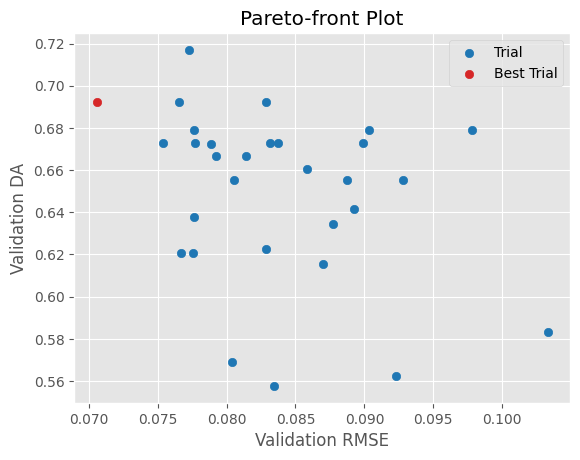

C:\Users\Acer\AppData\Local\Temp\ipykernel_6624\2350610360.py:13: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(


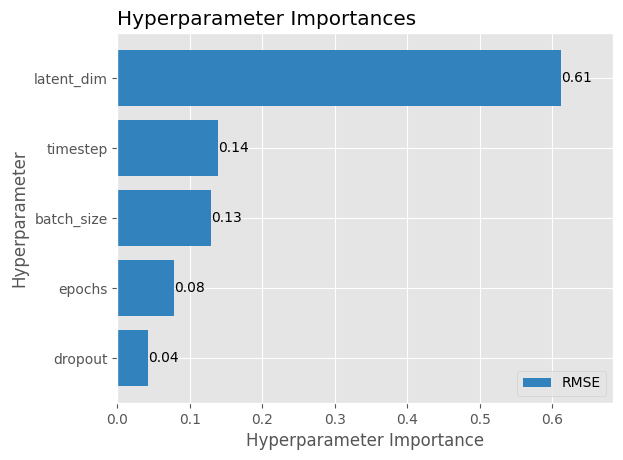

C:\Users\Acer\AppData\Local\Temp\ipykernel_6624\2350610360.py:21: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(


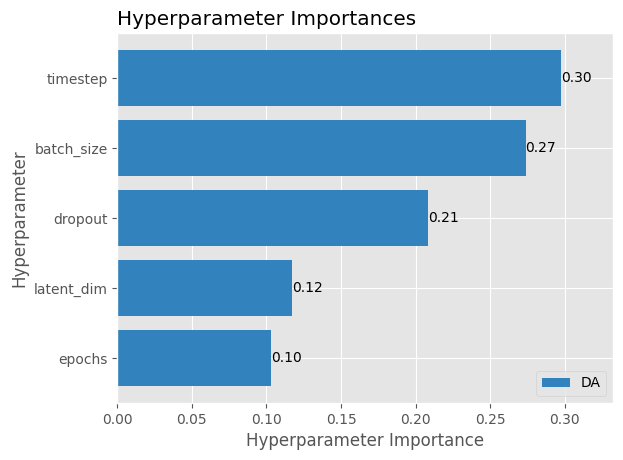

In [17]:
import matplotlib.pyplot as plt
import optuna

# 1. Plot Pareto Front (RMSE vs DA) — pakai targets eksplisit
optuna.visualization.matplotlib.plot_pareto_front(
    study,
    targets=lambda t: (t.value, t.user_attrs.get("val_da", 0.0)),
    target_names=["Validation RMSE", "Validation DA"]
)
plt.show()

# 2. Plot Hyperparameter Importance (RMSE)
optuna.visualization.matplotlib.plot_param_importances(
    study,
    target=lambda t: t.value,
    target_name="RMSE"
)
plt.show()

# 3. Plot Hyperparameter Importance (DA)
optuna.visualization.matplotlib.plot_param_importances(
    study,
    target=lambda t: t.user_attrs.get("val_da", 0.0),
    target_name="DA"
)
plt.show()

C:\Users\Acer\AppData\Local\Temp\ipykernel_6624\46736577.py:8: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  fig_rmse = optuna.visualization.matplotlib.plot_slice(


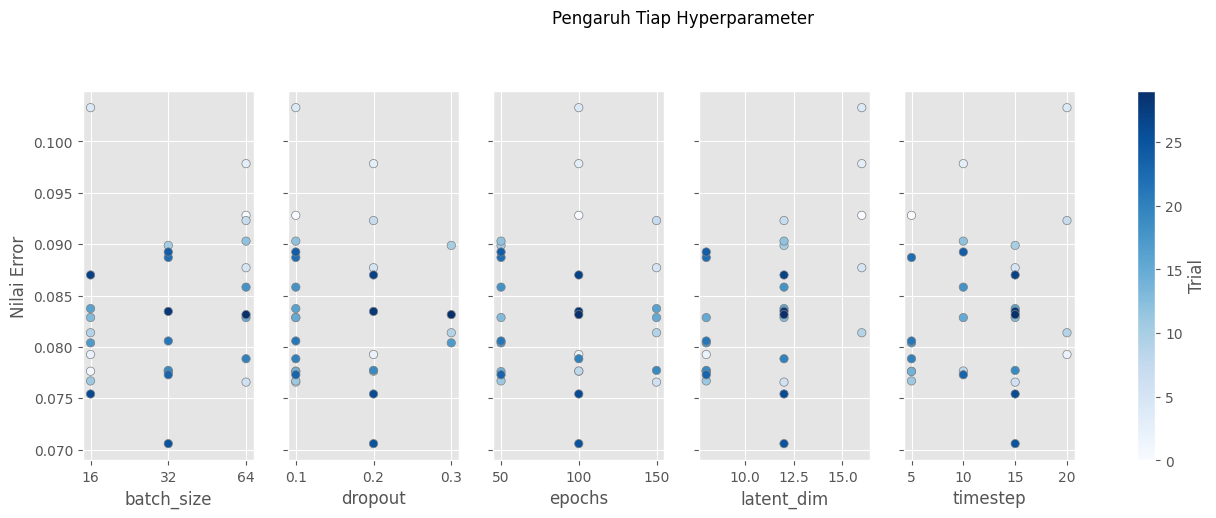

In [ ]:
import matplotlib.pyplot as plt
import optuna

# =========================================================
# 1. SLICE PLOT UNTUK RMSE (Semakin Rendah Semakin Bagus)
# =========================================================
# Menampilkan bagaimana pengaruh tiap parameter terhadap error RMSE
fig_rmse = optuna.visualization.matplotlib.plot_slice(
    study, 
    target=lambda t: t.values[0], 
    target_name="Nilai Error"
)
plt.suptitle("Pengaruh Tiap Hyperparameter", y=1.05)

plt.show()



# BASELINE MODEL DENGAN IndoBERT

In [ ]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

def evaluate_combined(y_true_scaled, y_pred_scaled, scaler, label='', prev_prices=None):
      
    # ==========================================================
    # 2. INVERSE TRANSFORM: Kembalikan ke Harga Aktual
    # ==========================================================
    y_true_inv_minmax = scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).flatten()
    y_pred_inv_minmax = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

    if prev_prices is not None:
        y_true_final = prev_prices * np.exp(y_true_inv_minmax)
        y_pred_final = prev_prices * np.exp(y_pred_inv_minmax)
        satuan = "Harga Asli (Rupiah)"
    else:
        y_true_final = y_true_inv_minmax
        y_pred_final = y_pred_inv_minmax
        satuan = "Log Return Asli"

    # ==========================================================
    # 3. EVALUASI AKTUAL: Hitung RMSE, MAPE, dan Metrik Lainnya
    # ==========================================================
    true_dir_scaled = np.diff(y_true_scaled.flatten())
    pred_dir_scaled = np.diff(y_pred_scaled.flatten())
    da_scaled = np.mean(np.sign(true_dir_scaled) == np.sign(pred_dir_scaled)) * 100

    mse  = mean_squared_error(y_true_final, y_pred_final)
    
    # Metrik Aktual yang diminta
    rmse_aktual = np.sqrt(mse)
    mape_aktual = mean_absolute_percentage_error(y_true_final, y_pred_final) * 100
    

    # ==========================================================
    # 4. TAMPILKAN HASIL GABUNGAN
    # ==========================================================
    print(f"\n=== Evaluasi BiLSTM — {label} ({satuan}) ===")
    print(f"RMSE : {rmse_aktual:.4f}")
    print(f"MAPE : {mape_aktual:.4f}%") 
    print(f"DA   : {da_scaled:.4f}%")    

    # ==========================================================
    # 5. KEMBALIKAN VARIABEL (Bisa dipakai untuk plot grafik)
    # ==========================================================
    return y_true_final, y_pred_final



In [ ]:
import numpy as np
import tensorflow as tf
from keras.models import Model
from keras.layers import (Input, Bidirectional, LSTM, Dense, Dropout, BatchNormalization)
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint


# ============================================================
# 1. BUAT SLIDING WINDOW LANGSUNG DARI X_scaled (TANPA VAE)
# ============================================================

# Gabungkan kembali Date dengan X_scaled
df_x_train_base = pd.read_csv('Data_Train_Final_minmax_indobert.csv')
df_x_train_base['Date'] = pd.to_datetime(df_x_train_base['Date'])
df_train_y_minmax = df_x_train_base[['Date', 'Close']]
df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])

df_x_val_base = pd.read_csv('Data_Val_Final_minmax_indobert.csv')
df_x_val_base['Date'] = pd.to_datetime(df_x_val_base['Date'])
df_val_y_minmax = df_x_val_base[['Date', 'Close']]
df_val_y_minmax['Date'] = pd.to_datetime(df_val_y_minmax['Date'])

df_x_test_base = pd.read_csv('Data_Test_Final_minmax_indobert.csv')
df_x_test_base['Date'] = pd.to_datetime(df_x_test_base['Date'])
df_test_y_minmax = df_x_test_base[['Date', 'Close']]
df_test_y_minmax['Date'] = pd.to_datetime(df_test_y_minmax['Date'])

# ============================================================
# 2. SLIDING WINDOW
# ============================================================

TIMESTEP = 15

print("=== Train ===")
X_train_base, y_train_base, date_train_base = create_sequences_safe(
    df_x_train_base, df_train_y_minmax, timestep=TIMESTEP
)
print("=== Validasi ===")
X_val_base, y_val_base, date_val_base = create_sequences_safe(
    df_x_val_base, df_val_y_minmax, timestep=TIMESTEP
)
print("=== Test ===")
X_test_base, y_test_base, date_test_base = create_sequences_safe(
    df_x_test_base, df_test_y_minmax, timestep=TIMESTEP
)

print("\n=== Shape Baseline ===")
print(f"X_train_base : {X_train_base.shape}")   # (557, 15, 6)
print(f"X_val_base   : {X_val_base.shape}")     # (56, 15, 6)
print(f"X_test_base  : {X_test_base.shape}")    # (57, 15, 6)

# ============================================================
# 3. ARSITEKTUR BASELINE BiLSTM
# ============================================================

tf.keras.backend.clear_session()

N_FITUR_BASE = X_train_base.shape[2]   # 6

inputs_base = Input(shape=(TIMESTEP, N_FITUR_BASE), name='input_layer')

x = Bidirectional(
        LSTM(16, return_sequences=False),
        name='bilstm_1'
    )(inputs_base)
# x = BatchNormalization()(x)
x = Dropout(0.2)(x)

x = Dense(8, activation='relu')(x)
output_base = Dense(1)(x)

model_base = Model(inputs_base, output_base, name='Baseline_BiLSTM')
model_base.summary()

model_base.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss      = tf.keras.losses.Huber(),
    metrics   = ['mae']
)

# ============================================================
# 4. TRAINING BASELINE
# ============================================================

callbacks_base = [
    EarlyStopping(monitor='val_loss', patience=25,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=7, min_lr=1e-6, verbose=1),
    ModelCheckpoint(filepath='best_baseline_bilstm_indobert.keras',
                    monitor='val_loss', save_best_only=True, verbose=1)
]

history_base = model_base.fit(
    X_train_base, y_train_base,
    validation_data = (X_val_base, y_val_base),
    epochs          = 100,
    batch_size      = 32,
    callbacks       = callbacks_base,
    verbose         = 1
)

# ============================================================
# 5. EVALUASI BASELINE
# ============================================================

y_pred_train_base = model_base.predict(X_train_base).flatten()
y_pred_val_base   = model_base.predict(X_val_base).flatten()
y_pred_test_base  = model_base.predict(X_test_base).flatten()

C:\Users\Acer\AppData\Local\Temp\ipykernel_31796\360374475.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])
C:\Users\Acer\AppData\Local\Temp\ipykernel_31796\360374475.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_val_y_minmax['Date'] = pd.to_datetime(df_val_y_minmax['Date'])
C:\Users\Acer\AppData\Local\Temp\ipykernel_31796\360374475.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataF

=== Train ===
  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00
=== Validasi ===
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00
=== Test ===
  Total baris setelah merge : 72
  Periode : 2025-01-06 00:00:00 → 2025-04-30 00:00:00

=== Shape Baseline ===
X_train_base : (557, 15, 6)
X_val_base   : (56, 15, 6)
X_test_base  : (57, 15, 6)


Model: "Baseline_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 15, 6)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1 (Bidirectional)        │ (None, 32)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,217 (12.57 KB)

 Trainable params: 3,217 (12.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
33/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1184 - mae: 0.4552
Epoch 1: val_loss improved from None to 0.00682, saving model to best_baseline_bilstm_indobert.keras

Epoch 1: finished saving model to best_baseline_bilstm_indobert.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0718 - mae: 0.3342 - val_loss: 0.0068 - val_mae: 0.0898 - learning_rate: 5.0000e-04
Epoch 2/100
30/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0152 - mae: 0.1393
Epoch 2: val_loss improved from 0.00682 to 0.00536, saving model to best_baseline_bilstm_indobert.keras

Epoch 2: finished saving model to best_baseline_bilstm_indobert.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0133 - mae: 0.1288 - val_loss: 0.0054 - val_mae: 0.0756 - learning_rate: 5.0000e-04
Epoch 3/100
31/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0099 - mae: 0.1109
Epoch 3: val_loss improved from 0.00536 to 0.00481, saving model to best_baseline_bilstm_indobert.keras

Epoch 3: finished saving model to best_ba

In [32]:
import pandas as pd

# ── 1. Handle kondisi Date sudah jadi index ────────────────────────────────
if df_harga_mentah.index.name == 'Date':
    # Date sudah jadi index, langsung normalize saja
    df_harga_mentah.index = pd.to_datetime(df_harga_mentah.index).tz_localize(None).normalize()
else:
    # Date masih jadi kolom biasa
    df_harga_mentah['Date'] = pd.to_datetime(df_harga_mentah['Date']).dt.tz_localize(None)
    df_harga_mentah.set_index('Date', inplace=True)
    df_harga_mentah.index = df_harga_mentah.index.normalize()

# ── 2. Shift untuk P_{t-1} ─────────────────────────────────────────────────
df_prev_close = df_harga_mentah['Close'].shift(1)

# ── 3. Konversi tanggal sekuens ────────────────────────────────────────────
tanggal_train = pd.to_datetime(date_train_base).tz_localize(None).normalize()
tanggal_val   = pd.to_datetime(date_val_base).tz_localize(None).normalize()
tanggal_test  = pd.to_datetime(date_test_base).tz_localize(None).normalize()

# ── DEBUG: cek kecocokan ───────────────────────────────────────────────────
print("Index df_prev_close (3 pertama):", df_prev_close.index[:3])
print("tanggal_test (3 pertama)        :", tanggal_test[:3])
print("Ada di index?                   :", tanggal_test[0] in df_prev_close.index)

# ── 4. Ambil nilai ─────────────────────────────────────────────────────────
harga_sebelumnya_train = df_prev_close.loc[tanggal_train].values
harga_sebelumnya_val   = df_prev_close.loc[tanggal_val].values
harga_sebelumnya_test  = df_prev_close.loc[tanggal_test].values

print(harga_sebelumnya_test.shape)
print(harga_sebelumnya_train.shape)
print(harga_sebelumnya_val.shape)

Index df_prev_close (3 pertama): DatetimeIndex(['2022-05-09', '2022-05-10', '2022-05-11'], dtype='datetime64[ns]', name='Date', freq=None)
tanggal_test (3 pertama)        : DatetimeIndex(['2025-01-30', '2025-01-31', '2025-02-03'], dtype='datetime64[ns]', freq=None)
Ada di index?                   : True
(57,)
(557,)
(56,)


In [ ]:
# Untuk data Test
y_test_asli, y_pred_test_asli = evaluate_combined(
    y_true_scaled=y_test_base, 
    y_pred_scaled=y_pred_test_base, 
    scaler=minmax_scaler_y, 
    label='Test', 
    prev_prices=harga_sebelumnya_test
)

# Untuk data Train
y_train_asli, y_pred_train_asli = evaluate_combined(
    y_true_scaled=y_train_base, 
    y_pred_scaled=y_pred_train_base, 
    scaler=minmax_scaler_y, 
    label='Train', 
    prev_prices=harga_sebelumnya_train
)


=== Evaluasi BiLSTM — Test (Harga Asli (Rupiah)) ===
RMSE : 3.3992
MAPE : 3.0920%
DA   : 51.5344%

=== Evaluasi BiLSTM — Train (Harga Asli (Rupiah)) ===
RMSE : 6.1913
MAPE : 3.2743%
DA   : 48.3813%


# BASELINE MODEL TANPA VAE

In [27]:
import joblib

minmax_scaler_y = joblib.load('minmax_scaler_y.pkl')

In [ ]:
import numpy as np
import tensorflow as tf
from keras.models import Model
from keras.layers import (Input, Bidirectional, LSTM, Dense, Dropout, BatchNormalization)
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint


# ============================================================
# 1. BUAT SLIDING WINDOW LANGSUNG DARI X_scaled (TANPA VAE)
# ============================================================

# Gabungkan kembali Date dengan X_scaled
df_x_train_base = pd.read_csv('Data_Train_Final_minmax.csv')
df_x_train_base['Date'] = pd.to_datetime(df_x_train_base['Date'])
df_train_y_minmax = df_x_train_base[['Date', 'Close']]
df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])

df_x_val_base = pd.read_csv('Data_Val_Final_minmax.csv')
df_x_val_base['Date'] = pd.to_datetime(df_x_val_base['Date'])
df_val_y_minmax = df_x_val_base[['Date', 'Close']]
df_val_y_minmax['Date'] = pd.to_datetime(df_val_y_minmax['Date'])

df_x_test_base = pd.read_csv('Data_Test_Final_minmax.csv')
df_x_test_base['Date'] = pd.to_datetime(df_x_test_base['Date'])
df_test_y_minmax = df_x_test_base[['Date', 'Close']]
df_test_y_minmax['Date'] = pd.to_datetime(df_test_y_minmax['Date'])

# ============================================================
# 2. SLIDING WINDOW
# ============================================================

TIMESTEP = 15

print("=== Train ===")
X_train_base, y_train_base, date_train_base = create_sequences_safe(
    df_x_train_base, df_train_y_minmax, timestep=TIMESTEP
)
print("=== Validasi ===")
X_val_base, y_val_base, date_val_base = create_sequences_safe(
    df_x_val_base, df_val_y_minmax, timestep=TIMESTEP
)
print("=== Test ===")
X_test_base, y_test_base, date_test_base = create_sequences_safe(
    df_x_test_base, df_test_y_minmax, timestep=TIMESTEP
)

print("\n=== Shape Baseline ===")
print(f"X_train_base : {X_train_base.shape}")   # (557, 15, 6)
print(f"X_val_base   : {X_val_base.shape}")     # (56, 15, 6)
print(f"X_test_base  : {X_test_base.shape}")    # (57, 15, 6)

# ============================================================
# 3. ARSITEKTUR BASELINE BiLSTM
# ============================================================

tf.keras.backend.clear_session()

N_FITUR_BASE = X_train_base.shape[2]   # 6

inputs_base = Input(shape=(TIMESTEP, N_FITUR_BASE), name='input_layer')

x = Bidirectional(
        LSTM(16, return_sequences=False),
        name='bilstm_1'
    )(inputs_base)
# x = BatchNormalization()(x)
x = Dropout(0.2)(x)

x = Dense(8, activation='relu')(x)
output_base = Dense(1)(x)

model_base = Model(inputs_base, output_base, name='Baseline_BiLSTM')
model_base.summary()

model_base.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss      = tf.keras.losses.Huber(),
    metrics   = ['mae']
)

# ============================================================
# 4. TRAINING BASELINE
# ============================================================

callbacks_base = [
    EarlyStopping(monitor='val_loss', patience=25,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=7, min_lr=1e-6, verbose=1),
    ModelCheckpoint(filepath='best_baseline_bilstm_no_vae.keras',
                    monitor='val_loss', save_best_only=True, verbose=1)
]

history_base = model_base.fit(
    X_train_base, y_train_base,
    validation_data = (X_val_base, y_val_base),
    epochs          = 100,
    batch_size      = 32,
    callbacks       = callbacks_base,
    verbose         = 1
)

# ============================================================
# 5. EVALUASI BASELINE
# ============================================================

y_pred_train_base = model_base.predict(X_train_base).flatten()
y_pred_val_base   = model_base.predict(X_val_base).flatten()
y_pred_test_base  = model_base.predict(X_test_base).flatten()


C:\Users\Acer\AppData\Local\Temp\ipykernel_31796\3418703999.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])
C:\Users\Acer\AppData\Local\Temp\ipykernel_31796\3418703999.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_val_y_minmax['Date'] = pd.to_datetime(df_val_y_minmax['Date'])
C:\Users\Acer\AppData\Local\Temp\ipykernel_31796\3418703999.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a Da

=== Train ===
  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00
=== Validasi ===
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00
=== Test ===
  Total baris setelah merge : 72
  Periode : 2025-01-06 00:00:00 → 2025-04-30 00:00:00

=== Shape Baseline ===
X_train_base : (557, 15, 6)
X_val_base   : (56, 15, 6)
X_test_base  : (57, 15, 6)


Model: "Baseline_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 15, 6)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1 (Bidirectional)        │ (None, 32)             │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,217 (12.57 KB)

 Trainable params: 3,217 (12.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
29/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0575 - mae: 0.2916
Epoch 1: val_loss improved from None to 0.00469, saving model to best_baseline_bilstm_no_vae.keras

Epoch 1: finished saving model to best_baseline_bilstm_no_vae.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0312 - mae: 0.1961 - val_loss: 0.0047 - val_mae: 0.0819 - learning_rate: 5.0000e-04
Epoch 2/100
28/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0103 - mae: 0.1174
Epoch 2: val_loss improved from 0.00469 to 0.00376, saving model to best_baseline_bilstm_no_vae.keras

Epoch 2: finished saving model to best_baseline_bilstm_no_vae.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0105 - mae: 0.1115 - val_loss: 0.0038 - val_mae: 0.0652 - learning_rate: 5.0000e-04
Epoch 3/100
27/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0081 - mae: 0.0982
Epoch 3: val_loss did not improve from 0.00376
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0071 - mae: 0.0912 - val_loss: 0.0041 - val_mae: 0.0689 - 

In [55]:
import pandas as pd

# 1. Pastikan kolom Date berformat datetime dan jadikan sebagai Index
# (Abaikan jika Date sudah menjadi index di df_harga_mentah)
# df_harga_mentah['Date'] = pd.to_datetime(df_harga_mentah['Date'])
# df_harga_mentah.set_index('Date', inplace=True)

# 2. Ambil hanya kolom Close dan geser 1 baris ke bawah (P_{t-1})
df_prev_close = df_harga_mentah['Close'].shift(1)

# 3. Ekstrak data P_{t-1} berdasarkan tanggal yang ada di sekuens masing-masing
# Asumsinya kamu punya variabel date_train_seq, date_val_seq, dan date_test_seq

# Konversi array tanggal menjadi DatetimeIndex agar cocok dengan index df_prev_close
tanggal_train = pd.to_datetime(date_train_base)
tanggal_val   = pd.to_datetime(date_val_base)
tanggal_test  = pd.to_datetime(date_test_base)

# Ambil nilainya
harga_sebelumnya_train = df_prev_close.loc[tanggal_train].values
harga_sebelumnya_val   = df_prev_close.loc[tanggal_val].values
harga_sebelumnya_test  = df_prev_close.loc[tanggal_test].values

# 4. Sekarang kamu bisa memasukkannya ke fungsi evaluasi yang tadi
# evaluate_proper(y_test_seq, y_pred_test, scaler=minmax_scaler_y, label='Test', prev_prices=harga_sebelumnya_test)
print(harga_sebelumnya_test.shape)
print(harga_sebelumnya_train.shape)
print(harga_sebelumnya_val.shape)

(57,)
(557,)
(56,)


In [ ]:
# Untuk data Test
y_test_asli, y_pred_test_asli = evaluate_combined(
    y_true_scaled=y_test_base, 
    y_pred_scaled=y_pred_test_base, 
    scaler=minmax_scaler_y, 
    label='Test', 
    prev_prices=harga_sebelumnya_test
)

# Untuk data Train
y_train_asli, y_pred_train_asli = evaluate_combined(
    y_true_scaled=y_train_base, 
    y_pred_scaled=y_pred_train_base, 
    scaler=minmax_scaler_y, 
    label='Train', 
    prev_prices=harga_sebelumnya_train
)

=== Evaluasi BiLSTM — Test (Harga Asli (Rupiah)) ===
RMSE : 3.3779
MAPE : 3.0724%
DA   : 51.3864%

=== Evaluasi BiLSTM — Train (Harga Asli (Rupiah)) ===
RMSE : 6.1247
MAPE : 3.0904%
DA   : 50.1223%


# BASELINE MODEL TANPA FinBERT

In [ ]:
import numpy as np
import tensorflow as tf
from keras.models import Model
from keras.layers import (Input, Bidirectional, LSTM, Dense, Dropout, BatchNormalization)
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint


# ============================================================
# 1. BUAT SLIDING WINDOW LANGSUNG DARI X_scaled (TANPA VAE)
# ============================================================

# Gabungkan kembali Date dengan X_scaled
df_x_train_base = pd.read_csv('Data_Train_VAE_minmax_no_finbert.csv')
df_x_train_base['Date'] = pd.to_datetime(df_x_train_base['Date'])
df_train_y_minmax = pd.read_csv('Data_Train_Final_minmax.csv', usecols=['Date', 'Close'])
df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])

df_x_val_base = pd.read_csv('Data_Val_VAE_minmax_no_finbert.csv')
df_x_val_base['Date'] = pd.to_datetime(df_x_val_base['Date'])
df_val_y_minmax = pd.read_csv('Data_Val_Final_minmax.csv', usecols=['Date', 'Close'])
df_val_y_minmax['Date'] = pd.to_datetime(df_val_y_minmax['Date'])

df_x_test_base = pd.read_csv('Data_Test_VAE_minmax_no_finbert.csv')
df_x_test_base['Date'] = pd.to_datetime(df_x_test_base['Date'])
df_test_y_minmax = pd.read_csv('Data_Test_Final_minmax.csv', usecols=['Date', 'Close'])
df_test_y_minmax['Date'] = pd.to_datetime(df_test_y_minmax['Date'])

# ============================================================
# 2. SLIDING WINDOW
# ============================================================

TIMESTEP = 15

print("=== Train ===")
X_train_base, y_train_base, date_train_base = create_sequences_safe(
    df_x_train_base, df_train_y_minmax, timestep=TIMESTEP
)
print("=== Validasi ===")
X_val_base, y_val_base, date_val_base = create_sequences_safe(
    df_x_val_base, df_val_y_minmax, timestep=TIMESTEP
)
print("=== Test ===")
X_test_base, y_test_base, date_test_base = create_sequences_safe(
    df_x_test_base, df_test_y_minmax, timestep=TIMESTEP
)

print("\n=== Shape Baseline ===")
print(f"X_train_base : {X_train_base.shape}")   # (557, 15, 6)
print(f"X_val_base   : {X_val_base.shape}")     # (56, 15, 6)
print(f"X_test_base  : {X_test_base.shape}")    # (57, 15, 6)

# ============================================================
# 3. ARSITEKTUR BASELINE BiLSTM
# ============================================================

tf.keras.backend.clear_session()

N_FITUR_BASE = X_train_base.shape[2]   # 12

inputs_base = Input(shape=(TIMESTEP, N_FITUR_BASE), name='input_layer')

x = Bidirectional(
        LSTM(16, return_sequences=False),
        name='bilstm_1'
    )(inputs_base)
# x = BatchNormalization()(x)
x = Dropout(0.2)(x)

x = Dense(8, activation='relu')(x)
output_base = Dense(1)(x)

model_base = Model(inputs_base, output_base, name='Baseline_BiLSTM')
model_base.summary()

model_base.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss      = tf.keras.losses.Huber(),
    metrics   = ['mae']
)

# ============================================================
# 4. TRAINING BASELINE
# ============================================================

callbacks_base = [
    EarlyStopping(monitor='val_loss', patience=25,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=7, min_lr=1e-6, verbose=1),
    ModelCheckpoint(filepath='best_baseline_bilstm_no_finbert.keras',
                    monitor='val_loss', save_best_only=True, verbose=1)
]

history_base = model_base.fit(
    X_train_base, y_train_base,
    validation_data = (X_val_base, y_val_base),
    epochs          = 100,
    batch_size      = 32,
    callbacks       = callbacks_base,
    verbose         = 1
)

# ============================================================
# 5. EVALUASI BASELINE
# ============================================================

y_pred_train_base = model_base.predict(X_train_base).flatten()
y_pred_val_base   = model_base.predict(X_val_base).flatten()
y_pred_test_base  = model_base.predict(X_test_base).flatten()

# evaluate_proper(y_train_base, y_pred_train_base, label='Baseline Train')
# evaluate_proper(y_val_base,   y_pred_val_base,   label='Baseline Validasi')
# evaluate_proper(y_test_base,  y_pred_test_base,  label='Baseline Test')

=== Train ===
  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00
=== Validasi ===
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00
=== Test ===
  Total baris setelah merge : 72
  Periode : 2025-01-06 00:00:00 → 2025-04-30 00:00:00

=== Shape Baseline ===
X_train_base : (557, 15, 12)
X_val_base   : (56, 15, 12)
X_test_base  : (57, 15, 12)


Model: "Baseline_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 15, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1 (Bidirectional)        │ (None, 32)             │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,985 (15.57 KB)

 Trainable params: 3,985 (15.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
30/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0540 - mae: 0.2971
Epoch 1: val_loss improved from None to 0.02850, saving model to best_baseline_bilstm_no_finbert.keras

Epoch 1: finished saving model to best_baseline_bilstm_no_finbert.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.0439 - mae: 0.2611 - val_loss: 0.0285 - val_mae: 0.2044 - learning_rate: 5.0000e-04
Epoch 2/100
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0261 - mae: 0.1908
Epoch 2: val_loss improved from 0.02850 to 0.01436, saving model to best_baseline_bilstm_no_finbert.keras

Epoch 2: finished saving model to best_baseline_bilstm_no_finbert.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0237 - mae: 0.1812 - val_loss: 0.0144 - val_mae: 0.1416 - learning_rate: 5.0000e-04
Epoch 3/100
27/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0173 - mae: 0.1524
Epoch 3: val_loss improved from 0.01436 to 0.01067, saving model to best_baseline_bilstm_no_finbert.keras

Epoch 3: finished saving model 

In [37]:
import pandas as pd

# 1. Pastikan kolom Date berformat datetime dan jadikan sebagai Index
# (Abaikan jika Date sudah menjadi index di df_harga_mentah)
# df_harga_mentah['Date'] = pd.to_datetime(df_harga_mentah['Date'])
# df_harga_mentah.set_index('Date', inplace=True)

# 2. Ambil hanya kolom Close dan geser 1 baris ke bawah (P_{t-1})
df_prev_close = df_harga_mentah['Close'].shift(1)

# 3. Ekstrak data P_{t-1} berdasarkan tanggal yang ada di sekuens masing-masing
# Asumsinya kamu punya variabel date_train_seq, date_val_seq, dan date_test_seq

# Konversi array tanggal menjadi DatetimeIndex agar cocok dengan index df_prev_close
tanggal_train = pd.to_datetime(date_train_base)
tanggal_val   = pd.to_datetime(date_val_base)
tanggal_test  = pd.to_datetime(date_test_base)

# Ambil nilainya
harga_sebelumnya_train = df_prev_close.loc[tanggal_train].values
harga_sebelumnya_val   = df_prev_close.loc[tanggal_val].values
harga_sebelumnya_test  = df_prev_close.loc[tanggal_test].values

# 4. Sekarang kamu bisa memasukkannya ke fungsi evaluasi yang tadi
# evaluate_proper(y_test_seq, y_pred_test, scaler=minmax_scaler_y, label='Test', prev_prices=harga_sebelumnya_test)
print(harga_sebelumnya_test.shape)
print(harga_sebelumnya_train.shape)
print(harga_sebelumnya_val.shape)

(57,)
(557,)
(56,)


In [ ]:
# Untuk data Test
y_test_asli, y_pred_test_asli = evaluate_combined(
    y_true_scaled=y_test_base, 
    y_pred_scaled=y_pred_test_base, 
    scaler=minmax_scaler_y, 
    label='Test', 
    prev_prices=harga_sebelumnya_test
)

# Untuk data Train
y_train_asli, y_pred_train_asli = evaluate_combined(
    y_true_scaled=y_train_base, 
    y_pred_scaled=y_pred_train_base, 
    scaler=minmax_scaler_y, 
    label='Train', 
    prev_prices=harga_sebelumnya_train
)

=== Evaluasi BiLSTM — Test (Harga Asli (Rupiah)) ===
RMSE : 3.3377
MAPE : 3.0608%
DA   : 50.2163%

=== Evaluasi BiLSTM — Train (Harga Asli (Rupiah)) ===
RMSE : 5.2707
MAPE : 2.5443%
DA   : 49.1223%


# BILSTM PREDIKSI CBNC

In [29]:
import numpy as np
import tensorflow as tf
from keras.models import Model
from keras.layers import (Input, Bidirectional, LSTM, Dense, Dropout, BatchNormalization)
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint


# ============================================================
# 1. BUAT SLIDING WINDOW LANGSUNG DARI X_scaled (TANPA VAE)
# ============================================================

# Gabungkan kembali Date dengan X_scaled
df_x_train_base = pd.read_csv('Data_Train_VAE_minmax_cbnc.csv')
df_x_train_base['Date'] = pd.to_datetime(df_x_train_base['Date'])
df_train_y_minmax = pd.read_csv('Data_Train_Final_minmax_cbnc.csv', usecols=['Date', 'Close'])
df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])

df_x_val_base = pd.read_csv('Data_Val_VAE_minmax_cbnc.csv')
df_x_val_base['Date'] = pd.to_datetime(df_x_val_base['Date'])
df_val_y_minmax = pd.read_csv('Data_Val_Final_minmax_cbnc.csv', usecols=['Date', 'Close'])
df_val_y_minmax['Date'] = pd.to_datetime(df_val_y_minmax['Date'])

df_x_test_base = pd.read_csv('Data_Test_VAE_minmax_cbnc.csv')
df_x_test_base['Date'] = pd.to_datetime(df_x_test_base['Date'])
df_test_y_minmax = pd.read_csv('Data_Test_Final_minmax_cbnc.csv', usecols=['Date', 'Close'])
df_test_y_minmax['Date'] = pd.to_datetime(df_test_y_minmax['Date'])

# ============================================================
# 2. SLIDING WINDOW
# ============================================================

TIMESTEP = 15

print("=== Train ===")
X_train_base, y_train_base, date_train_base = create_sequences_safe(
    df_x_train_base, df_train_y_minmax, timestep=TIMESTEP
)
print("=== Validasi ===")
X_val_base, y_val_base, date_val_base = create_sequences_safe(
    df_x_val_base, df_val_y_minmax, timestep=TIMESTEP
)
print("=== Test ===")
X_test_base, y_test_base, date_test_base = create_sequences_safe(
    df_x_test_base, df_test_y_minmax, timestep=TIMESTEP
)

print("\n=== Shape Baseline ===")
print(f"X_train_base : {X_train_base.shape}")   # (557, 15, 6)
print(f"X_val_base   : {X_val_base.shape}")     # (56, 15, 6)
print(f"X_test_base  : {X_test_base.shape}")    # (57, 15, 6)

# ============================================================
# 3. ARSITEKTUR BASELINE BiLSTM
# ============================================================

tf.keras.backend.clear_session()

N_FITUR_BASE = X_train_base.shape[2]   # 12

inputs_base = Input(shape=(TIMESTEP, N_FITUR_BASE), name='input_layer')

x = Bidirectional(
        LSTM(16, return_sequences=False),
        name='bilstm_1'
    )(inputs_base)
# x = BatchNormalization()(x)
x = Dropout(0.2)(x)

x = Dense(8, activation='relu')(x)
output_base = Dense(1)(x)

model_base = Model(inputs_base, output_base, name='Baseline_BiLSTM')
model_base.summary()

model_base.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss      = tf.keras.losses.Huber(),
    metrics   = ['mae']
)

# ============================================================
# 4. TRAINING BASELINE
# ============================================================

callbacks_base = [
    EarlyStopping(monitor='val_loss', patience=25,
                  restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=7, min_lr=1e-6, verbose=1),
    ModelCheckpoint(filepath='best_baseline_bilstm_no_finbert.keras',
                    monitor='val_loss', save_best_only=True, verbose=1)
]

history_base = model_base.fit(
    X_train_base, y_train_base,
    validation_data = (X_val_base, y_val_base),
    epochs          = 100,
    batch_size      = 32,
    callbacks       = callbacks_base,
    verbose         = 1
)

# ============================================================
# 5. EVALUASI BASELINE
# ============================================================

y_pred_train_base = model_base.predict(X_train_base).flatten()
y_pred_val_base   = model_base.predict(X_val_base).flatten()
y_pred_test_base  = model_base.predict(X_test_base).flatten()

# evaluate_proper(y_train_base, y_pred_train_base, label='Baseline Train')
# evaluate_proper(y_val_base,   y_pred_val_base,   label='Baseline Validasi')
# evaluate_proper(y_test_base,  y_pred_test_base,  label='Baseline Test')

=== Train ===
  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00
=== Validasi ===
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00
=== Test ===
  Total baris setelah merge : 72
  Periode : 2025-01-06 00:00:00 → 2025-04-30 00:00:00

=== Shape Baseline ===
X_train_base : (557, 15, 12)
X_val_base   : (56, 15, 12)
X_test_base  : (57, 15, 12)


Model: "Baseline_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 15, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1 (Bidirectional)        │ (None, 32)             │         3,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,985 (15.57 KB)

 Trainable params: 3,985 (15.57 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
11/18 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0579 - mae: 0.2905
Epoch 1: val_loss improved from None to 0.08798, saving model to best_baseline_bilstm_no_finbert.keras

Epoch 1: finished saving model to best_baseline_bilstm_no_finbert.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - loss: 0.0528 - mae: 0.2725 - val_loss: 0.0880 - val_mae: 0.3854 - learning_rate: 5.0000e-04
Epoch 2/100
13/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0407 - mae: 0.2416 
Epoch 2: val_loss improved from 0.08798 to 0.06609, saving model to best_baseline_bilstm_no_finbert.keras

Epoch 2: finished saving model to best_baseline_bilstm_no_finbert.keras
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0387 - mae: 0.2304 - val_loss: 0.0661 - val_mae: 0.3279 - learning_rate: 5.0000e-04
Epoch 3/100
13/18 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0350 - mae: 0.2108 
Epoch 3: val_loss improved from 0.06609 to 0.05175, saving model to best_baseline_bilstm_no_finbert.keras

Epoch 3: finished saving mode

In [31]:
import pandas as pd

# 1. Pastikan kolom Date berformat datetime dan jadikan sebagai Index
# (Abaikan jika Date sudah menjadi index di df_harga_mentah)
df_harga_mentah['Date'] = pd.to_datetime(df_harga_mentah['Date'])
df_harga_mentah.set_index('Date', inplace=True)

# 2. Ambil hanya kolom Close dan geser 1 baris ke bawah (P_{t-1})
df_prev_close = df_harga_mentah['Close'].shift(1)

# 3. Ekstrak data P_{t-1} berdasarkan tanggal yang ada di sekuens masing-masing
# Asumsinya kamu punya variabel date_train_seq, date_val_seq, dan date_test_seq

# Konversi array tanggal menjadi DatetimeIndex agar cocok dengan index df_prev_close
tanggal_train = pd.to_datetime(date_train_base)
tanggal_val   = pd.to_datetime(date_val_base)
tanggal_test  = pd.to_datetime(date_test_base)

# Ambil nilainya
harga_sebelumnya_train = df_prev_close.loc[tanggal_train].values
harga_sebelumnya_val   = df_prev_close.loc[tanggal_val].values
harga_sebelumnya_test  = df_prev_close.loc[tanggal_test].values

# 4. Sekarang kamu bisa memasukkannya ke fungsi evaluasi yang tadi
# evaluate_proper(y_test_seq, y_pred_test, scaler=minmax_scaler_y, label='Test', prev_prices=harga_sebelumnya_test)
print(harga_sebelumnya_test.shape)
print(harga_sebelumnya_train.shape)
print(harga_sebelumnya_val.shape)

(57,)
(557,)
(56,)


In [ ]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

def evaluate_combined(y_true_scaled, y_pred_scaled, scaler, label='', prev_prices=None):
   
    # ==========================================================
    # 2. INVERSE TRANSFORM: Kembalikan ke Harga Aktual
    # ==========================================================
    y_true_inv_minmax = scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).flatten()
    y_pred_inv_minmax = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

    if prev_prices is not None:
        y_true_final = prev_prices * np.exp(y_true_inv_minmax)
        y_pred_final = prev_prices * np.exp(y_pred_inv_minmax)
        satuan = "Harga Asli (Rupiah)"
    else:
        y_true_final = y_true_inv_minmax
        y_pred_final = y_pred_inv_minmax
        satuan = "Log Return Asli"

    # ==========================================================
    # 3. EVALUASI AKTUAL: Hitung RMSE, MAPE, dan Metrik Lainnya
    # ==========================================================
    true_dir_scaled = np.diff(y_true_scaled.flatten())
    pred_dir_scaled = np.diff(y_pred_scaled.flatten())
    da_scaled = np.mean(np.sign(true_dir_scaled) == np.sign(pred_dir_scaled)) * 100

    mse  = mean_squared_error(y_true_final, y_pred_final)
    
    # Metrik Aktual yang diminta
    rmse_aktual = np.sqrt(mse)
    mape_aktual = mean_absolute_percentage_error(y_true_final, y_pred_final) * 100
    

    # ==========================================================
    # 4. TAMPILKAN HASIL GABUNGAN
    # ==========================================================
    print(f"\n=== Evaluasi BiLSTM — {label} ({satuan}) ===")
    print(f"RMSE : {rmse_aktual:.4f}")
    print(f"MAPE : {mape_aktual:.4f}%") 
    print(f"DA   : {da_scaled:.4f}%")    

    # ==========================================================
    # 5. KEMBALIKAN VARIABEL (Bisa dipakai untuk plot grafik)
    # ==========================================================
    return y_true_final, y_pred_final


In [34]:
# Untuk data Test
y_test_asli, y_pred_test_asli = evaluate_combined(
    y_true_scaled=y_test_base, 
    y_pred_scaled=y_pred_test_base, 
    scaler=minmax_scaler_y, 
    label='Test', 
    prev_prices=harga_sebelumnya_test
)

# Untuk data Train
y_train_asli, y_pred_train_asli = evaluate_combined(
    y_true_scaled=y_train_base, 
    y_pred_scaled=y_pred_train_base, 
    scaler=minmax_scaler_y, 
    label='Train', 
    prev_prices=harga_sebelumnya_train
)


=== Evaluasi BiLSTM — Test (Harga Asli (Rupiah)) ===
RMSE : 3.4987
MAPE : 3.2866%
DA   : 57.1429%

=== Evaluasi BiLSTM — Train (Harga Asli (Rupiah)) ===
RMSE : 5.1437
MAPE : 2.4381%
DA   : 61.6906%


# BiLSTM PREDIKSI

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from keras.models import Model
from keras.layers import (Input, Bidirectional, LSTM, Dense, Dropout, BatchNormalization)
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# ============================================================
# 1. BUAT SLIDING WINDOW LANGSUNG DARI X_scaled (TANPA VAE)
# ============================================================

# Gabungkan kembali Date dengan X_scaled
df_z_train = pd.read_csv('Data_Train_VAE_minmax_4.csv')
df_z_train['Date'] = pd.to_datetime(df_z_train['Date'])
df_train_y_minmax = pd.read_csv('Data_Train_Final_minmax.csv', usecols=['Date', 'Close'])
df_train_y_minmax['Date'] = pd.to_datetime(df_train_y_minmax['Date'])

df_z_val = pd.read_csv('Data_Val_VAE_minmax_4.csv')
df_z_val['Date'] = pd.to_datetime(df_z_val['Date'])
df_val_y_minmax = pd.read_csv('Data_Val_Final_minmax.csv', usecols=['Date', 'Close'])
df_val_y_minmax['Date'] = pd.to_datetime(df_val_y_minmax['Date'])

df_z_test = pd.read_csv('Data_Test_VAE_minmax_4.csv')
df_z_test['Date'] = pd.to_datetime(df_z_test['Date'])
df_test_y_minmax = pd.read_csv('Data_Test_Final_minmax.csv', usecols=['Date', 'Close'])
df_test_y_minmax['Date'] = pd.to_datetime(df_test_y_minmax['Date'])

# ============================================================
# 2. SLIDING WINDOW
# ============================================================

TIMESTEP = 15

print("=== Train ===")
X_train_seq, y_train_seq, date_train_seq = create_sequences_safe(
    df_z_train, df_train_y_minmax, timestep=TIMESTEP
)

print("\n=== Validasi ===")
X_val_seq, y_val_seq, date_val_seq = create_sequences_safe(
    df_z_val, df_val_y_minmax, timestep=TIMESTEP
)

print("\n=== Test ===")
X_test_seq, y_test_seq, date_test_seq = create_sequences_safe(
    df_z_test, df_test_y_minmax, timestep=TIMESTEP
)

print("\n=== Shape Baseline ===")
print(f"X_train_seq : {X_train_seq.shape}")   # (557, 15, 12)
print(f"X_val_seq   : {X_val_seq.shape}")     # (56, 15, 12)
print(f"X_test_seq  : {X_test_seq.shape}")    # (57, 15, 12)

# ============================================================
# 1. PARAMETER BILSTM
# ============================================================

TIMESTEP   = 15
N_FITUR    = X_train_seq.shape[2]   # 12 (z_laten)
UNITS_1    = 16                    # unit layer BiLSTM pertama
DROPOUT    = 0.2                    # dropout rate
EPOCHS     = 100
BATCH_SIZE = 32

# ============================================================
# 2. ARSITEKTUR BILSTM
# ============================================================
tf.keras.backend.clear_session()
inputs = Input(shape=(TIMESTEP, N_FITUR), name='input_layer')

# Layer BiLSTM pertama
x = Bidirectional(
        LSTM(UNITS_1, return_sequences=False),
        name='bilstm_1'
    )(inputs)
# x = BatchNormalization()(x)
x = Dropout(DROPOUT)(x)

# Layer Dense
x = Dense(8, activation='relu', name='dense_1')(x)
output = Dense(1, name='output')(x)

model_bilstm = Model(inputs, output, name='VAE_BiLSTM')
model_bilstm.summary()

# ============================================================
# 3. COMPILE MODEL
# ============================================================

model_bilstm.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss      = tf.keras.losses.Huber(),
    metrics   = ['mae']
)

# ============================================================
# 4. CALLBACKS
# ============================================================

callbacks = [
    # Hentikan training jika val_loss tidak membaik selama 15 epoch
    EarlyStopping(
        monitor              = 'val_loss',
        patience             = 25,
        restore_best_weights = True,
        verbose              = 1
    ),
    # Kurangi learning rate jika val_loss stagnan selama 7 epoch
    ReduceLROnPlateau(
        monitor  = 'val_loss',
        factor   = 0.5,
        patience = 7,
        min_lr   = 1e-6,
        verbose  = 1
    ),
    # Simpan model terbaik
    ModelCheckpoint(
        filepath          = 'best_vae_bilstm_tes.keras',
        monitor           = 'val_loss',
        save_best_only    = True,
        verbose           = 1
    )
]

# ============================================================
# 5. TRAINING BILSTM
# ============================================================

history = model_bilstm.fit(
    X_train_seq, y_train_seq,
    validation_data = (X_val_seq, y_val_seq),
    epochs          = EPOCHS,
    batch_size      = BATCH_SIZE,
    callbacks       = callbacks,
    verbose         = 1
)

# ============================================================
# 6. PREDIKSI
# ============================================================

y_pred_train = model_bilstm.predict(X_train_seq)   # (562, 1)
y_pred_val   = model_bilstm.predict(X_val_seq)     # (61, 1)
y_pred_test  = model_bilstm.predict(X_test_seq)    # (62, 1)

# Flatten → 1D
y_pred_train = y_pred_train.flatten()   # (562,)
y_pred_val   = y_pred_val.flatten()     # (61,)
y_pred_test  = y_pred_test.flatten()    # (62,)

=== Train ===
  Total baris setelah merge : 572
  Periode : 2022-05-10 00:00:00 → 2024-09-19 00:00:00

=== Validasi ===
  Total baris setelah merge : 71
  Periode : 2024-09-20 00:00:00 → 2025-01-03 00:00:00

=== Test ===
  Total baris setelah merge : 72
  Periode : 2025-01-06 00:00:00 → 2025-04-30 00:00:00

=== Shape Baseline ===
X_train_seq : (557, 15, 12)
X_val_seq   : (56, 15, 12)
X_test_seq  : (57, 15, 12)


Model: "VAE_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 15, 12)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_1 (Bidirectional)        │ (None, 16)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,489 (5.82 KB)

 Trainable params: 1,489 (5.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0879 - mae: 0.3679
Epoch 1: val_loss improved from None to 0.03381, saving model to best_vae_bilstm_tes.keras

Epoch 1: finished saving model to best_vae_bilstm_tes.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - loss: 0.0725 - mae: 0.3315 - val_loss: 0.0338 - val_mae: 0.2235 - learning_rate: 5.0000e-04
Epoch 2/150
24/35 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0526 - mae: 0.2713
Epoch 2: val_loss improved from 0.03381 to 0.01585, saving model to best_vae_bilstm_tes.keras

Epoch 2: finished saving model to best_vae_bilstm_tes.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0404 - mae: 0.2324 - val_loss: 0.0158 - val_mae: 0.1427 - learning_rate: 5.0000e-04
Epoch 3/150
23/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0251 - mae: 0.1796
Epoch 3: val_loss improved from 0.01585 to 0.01037, saving model to best_vae_bilstm_tes.keras

Epoch 3: finished saving model to best_vae_bilstm_tes.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 8

In [38]:
model_bilstm.save('model_vae_bilstm_f4.keras')

# EVALUASI HASIL

In [10]:
import pandas as pd

# 1. Pastikan kolom Date berformat datetime dan jadikan sebagai Index
# (Abaikan jika Date sudah menjadi index di df_harga_mentah)
df_harga_mentah['Date'] = pd.to_datetime(df_harga_mentah['Date'])
df_harga_mentah.set_index('Date', inplace=True)

# 2. Ambil hanya kolom Close dan geser 1 baris ke bawah (P_{t-1})
df_prev_close = df_harga_mentah['Close'].shift(1)

# 3. Ekstrak data P_{t-1} berdasarkan tanggal yang ada di sekuens masing-masing
# Asumsinya kamu punya variabel date_train_seq, date_val_seq, dan date_test_seq

# Konversi array tanggal menjadi DatetimeIndex agar cocok dengan index df_prev_close
tanggal_train = pd.to_datetime(date_train_seq)
tanggal_val   = pd.to_datetime(date_val_seq)
tanggal_test  = pd.to_datetime(date_test_seq)

# Ambil nilainya
harga_sebelumnya_train = df_prev_close.loc[tanggal_train].values
harga_sebelumnya_val   = df_prev_close.loc[tanggal_val].values
harga_sebelumnya_test  = df_prev_close.loc[tanggal_test].values

# 4. Sekarang kamu bisa memasukkannya ke fungsi evaluasi yang tadi
# evaluate_proper(y_test_seq, y_pred_test, scaler=minmax_scaler_y, label='Test', prev_prices=harga_sebelumnya_test)
print(harga_sebelumnya_test.shape)
print(harga_sebelumnya_train.shape)
print(harga_sebelumnya_val.shape)

(57,)
(557,)
(56,)


In [11]:
import joblib

minmax_scaler_y = joblib.load('minmax_scaler_y.pkl')

In [ ]:
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

def evaluate_combined(y_true_scaled, y_pred_scaled, scaler, label='', prev_prices=None):
 
    # ==========================================================
    # 2. INVERSE TRANSFORM: Kembalikan ke Harga Aktual
    # ==========================================================
    y_true_inv_minmax = scaler.inverse_transform(y_true_scaled.reshape(-1, 1)).flatten()
    y_pred_inv_minmax = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).flatten()

    if prev_prices is not None:
        y_true_final = prev_prices * np.exp(y_true_inv_minmax)
        y_pred_final = prev_prices * np.exp(y_pred_inv_minmax)
        satuan = "Harga Asli (Rupiah)"
    else:
        y_true_final = y_true_inv_minmax
        y_pred_final = y_pred_inv_minmax
        satuan = "Log Return Asli"

    # ==========================================================
    # 3. EVALUASI AKTUAL: Hitung RMSE, MAPE, dan Metrik Lainnya
    # ==========================================================
    true_dir_scaled = np.diff(y_true_scaled.flatten())
    pred_dir_scaled = np.diff(y_pred_scaled.flatten())
    da_scaled = np.mean(np.sign(true_dir_scaled) == np.sign(pred_dir_scaled)) * 100

    mse  = mean_squared_error(y_true_final, y_pred_final)
    
    # Metrik Aktual yang diminta
    rmse_aktual = np.sqrt(mse)
    mape_aktual = mean_absolute_percentage_error(y_true_final, y_pred_final) * 100
    

    # ==========================================================
    # 4. TAMPILKAN HASIL GABUNGAN
    # ==========================================================
    print(f"\n=== Evaluasi BiLSTM — {label} ({satuan}) ===")
    print(f"RMSE : {rmse_aktual:.4f}")
    print(f"MAPE : {mape_aktual:.4f}%") 
    print(f"DA   : {da_scaled:.4f}%")    

    # ==========================================================
    # 5. KEMBALIKAN VARIABEL (Bisa dipakai untuk plot grafik)
    # ==========================================================
    return y_true_final, y_pred_final


# ==========================================================
# CARA MEMANGGIL FUNGSI
# ==========================================================

# Untuk data Test
y_test_asli, y_pred_test_asli = evaluate_combined(
    y_true_scaled=y_test_seq, 
    y_pred_scaled=y_pred_test, 
    scaler=minmax_scaler_y, 
    label='Test', 
    prev_prices=harga_sebelumnya_test
)

# Untuk data Train
y_train_asli, y_pred_train_asli = evaluate_combined(
    y_true_scaled=y_train_seq, 
    y_pred_scaled=y_pred_train, 
    scaler=minmax_scaler_y, 
    label='Train', 
    prev_prices=harga_sebelumnya_train
)


=== Evaluasi BiLSTM — Test (Harga Asli (Rupiah)) ===
RMSE : 3.2736
MAPE : 3.0181%
DA   : 55.3571%

=== Evaluasi BiLSTM — Train (Harga Asli (Rupiah)) ===
RMSE : 4.9411
MAPE : 2.3052%
DA   : 63.1295%


# GRAFIK PERBANDINGAN

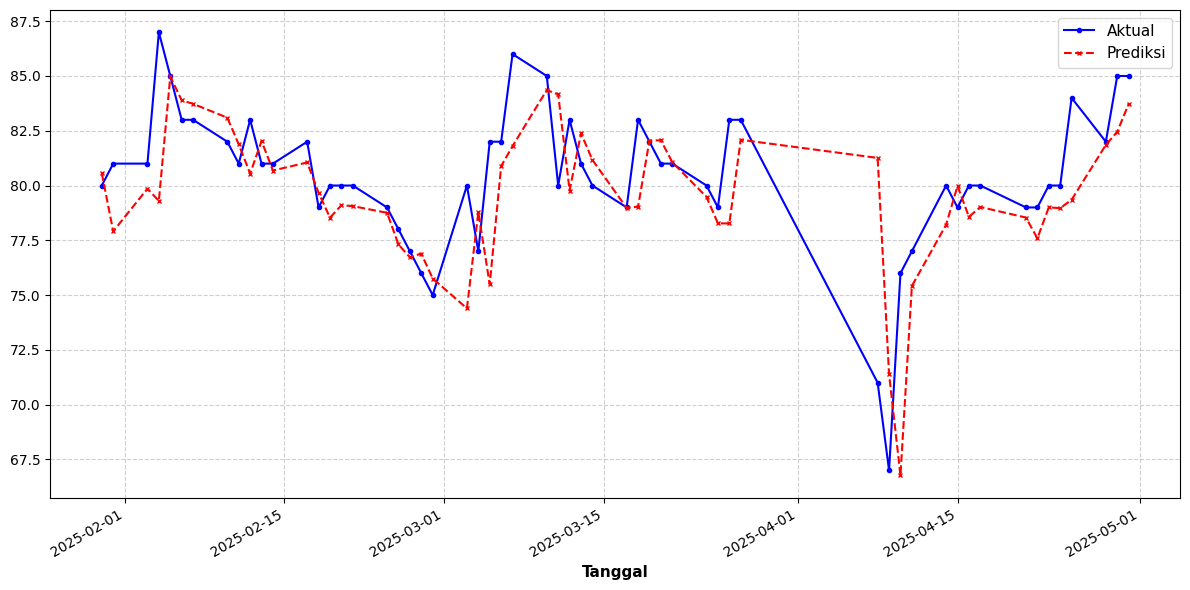

In [37]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Pastikan array tanggal berformat Datetime agar rapi di Matplotlib
tanggal_plot = pd.to_datetime(date_test_seq)

# 2. Ratakan array (flatten) menjadi 1D agar tidak ada error dimensi saat di-plot
y_test_plot = y_test_asli.flatten()
y_pred_plot = y_pred_test_asli.flatten()

# 3. Mulai membuat grafik
plt.figure(figsize=(12, 6))

# Plot nilai Target Aktual
plt.plot(tanggal_plot, y_test_plot, label='Aktual', 
         color='blue', linewidth=1.5, marker='o', markersize=3)

# Plot nilai Prediksi Model
plt.plot(tanggal_plot, y_pred_plot, label='Prediksi', 
         color='red', linewidth=1.5, linestyle='--', marker='x', markersize=3)

# 4. Estetika Grafik
# plt.title('Perbandingan Aktual vs Prediksi pada Skala Model (Scaled Log Return)', 
#           fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tanggal', fontsize=11, fontweight='bold')
# plt.ylabel('Nilai Scaled Log Return', fontsize=11, fontweight='bold')

# Memiringkan teks tanggal secara otomatis agar tidak saling tumpang tindih
plt.gcf().autofmt_xdate()

# Tambahkan grid dan legend
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best', fontsize=11)

# Tampilkan grafik
plt.tight_layout()
plt.show()

# ANALISIS GROUPSHAP

=== Shape Data Test untuk GroupSHAP ===
X_test_asli : (57, 15, 6)
X_test_flat : (57, 90)

=== Verifikasi Grup ===
Grup OHLC     : 60 kolom
Grup Volume   : 15 kolom
Grup Sentimen : 15 kolom
Total         : 90 == 90 ✅

Menghitung SHAP values pada data test...


  0%|          | 0/57 [00:00<?, ?it/s]c:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 3 iterations, i.e. alpha=3.287e-03, with an active set of 3 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 6 iterations, i.e. alpha=1.829e-03, with an active set of 6 regressors, and the smallest cholesky pivot element being 2.220e-16. Reduce max_iter or increase eps parameters.
  warnings.warn(
c:\Users\Acer\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a re

SHAP values shape : (57, 90)

=== Hasil GroupSHAP — Data Test ===
    Grup  Mean|SHAP|  Arah (signed)
    OHLC    0.086887      -0.000626
Sentimen    0.020307      -0.002798
  Volume    0.018328       0.000717


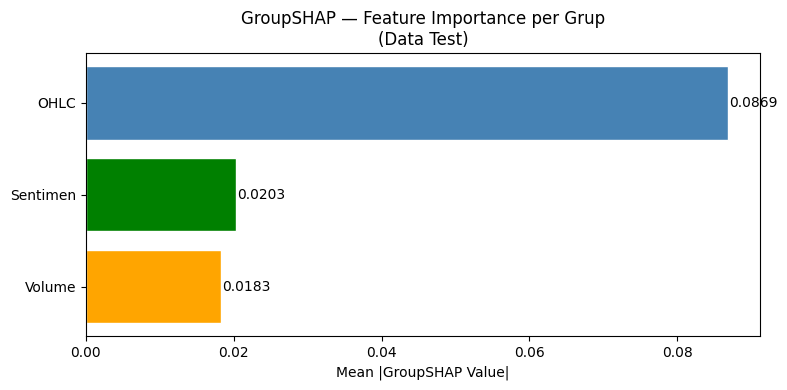

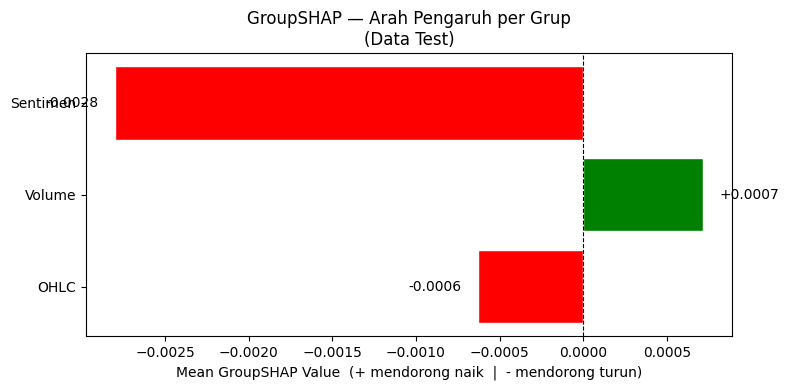

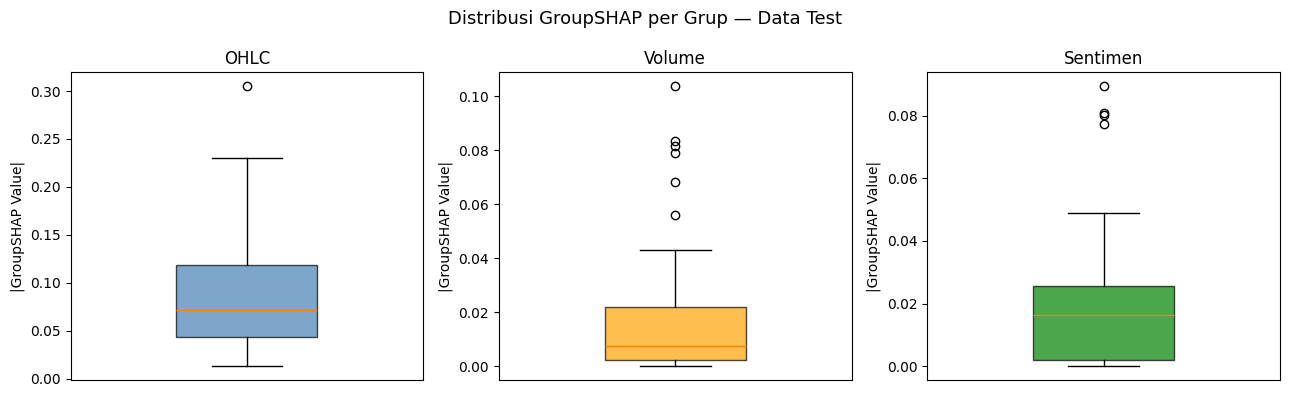

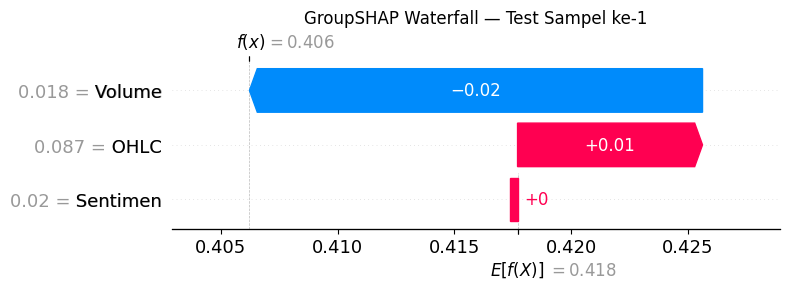

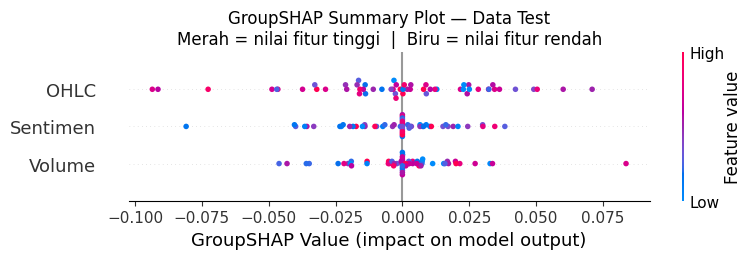

In [ ]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. PARAMETER
# ============================================================

FITUR_ASLI   = ['Open', 'High', 'Low', 'Close', 'Volume', 'Nilai_Sentimen']
N_FITUR_ASLI = len(FITUR_ASLI)        # 6
TIMESTEP     = X_train_seq.shape[1]   # 15
N_LATEN      = X_train_seq.shape[2]   # 12
NAMA_GRUP    = ['OHLC', 'Volume', 'Sentimen']

# ============================================================
# 2. BUAT SLIDING WINDOW DARI FITUR ASLI (DATA TEST SAJA)
# ============================================================

def create_sequences_shap(df_x, timestep):
    X     = df_x.drop(columns=['Date']).values
    X_seq = []
    for i in range(len(X) - timestep):
        X_seq.append(X[i : i + timestep])
    return np.array(X_seq)

X_test_asli = create_sequences_shap(df_test_final, timestep=TIMESTEP)
X_test_flat = X_test_asli.reshape(X_test_asli.shape[0], -1)

print("=== Shape Data Test untuk GroupSHAP ===")
print(f"X_test_asli : {X_test_asli.shape}")   # (62, 15, 12)
print(f"X_test_flat : {X_test_flat.shape}")   # (62, 180)

# ============================================================
# 3. DEFINISI GRUP
# ============================================================

# Grup 1 — OHLC 
grup_ohlc = [t * N_FITUR_ASLI + f for t in range(TIMESTEP) for f in [0, 1, 2, 3]]

# Grup 2 — Volume 
grup_volume = [t * N_FITUR_ASLI + 4 for t in range(TIMESTEP)]

# Grup 3 — Sentimen 
grup_sentimen = [t * N_FITUR_ASLI + 5 for t in range(TIMESTEP)]

groups = [grup_ohlc, grup_volume, grup_sentimen]

print("\n=== Verifikasi Grup ===")
print(f"Grup OHLC     : {len(grup_ohlc)} kolom")
print(f"Grup Volume   : {len(grup_volume)} kolom")
print(f"Grup Sentimen : {len(grup_sentimen)} kolom")
print(f"Total         : {len(grup_ohlc)+len(grup_volume)+len(grup_sentimen)} == {X_test_flat.shape[1]} ✅")

# ============================================================
# 4. WRAPPER MODEL
# ============================================================

def predict_dari_fitur_asli(X_flat):
    n_sampel   = X_flat.shape[0]
    X_3d       = X_flat.reshape(n_sampel, TIMESTEP, N_FITUR_ASLI)
    X_2d       = X_3d.reshape(n_sampel * TIMESTEP, N_FITUR_ASLI)
    _, _, z_2d = encoder.predict(X_2d, verbose=0)
    z_3d       = z_2d.reshape(n_sampel, TIMESTEP, N_LATEN)
    return model_bilstm.predict(z_3d, verbose=0).flatten()

# ============================================================
# 5. HITUNG SHAP
# ============================================================

# Background dari data test (lebih kecil = lebih cepat)
background = shap.sample(X_test_flat, 10)

explainer = shap.KernelExplainer(predict_dari_fitur_asli, background)

print("\nMenghitung SHAP values pada data test...")
shap_test_vals = explainer.shap_values(X_test_flat, nsamples=25)

print(f"SHAP values shape : {shap_test_vals.shape}")   # (62, 180)

# ============================================================
# 6. AGREGASI KE GRUP
# ============================================================

def hitung_group_shap(shap_vals, groups, group_names):
    n_sampel          = shap_vals.shape[0]
    group_shap_signed = np.zeros((n_sampel, len(groups)))
    group_shap_abs    = np.zeros((n_sampel, len(groups)))
    for i, grp in enumerate(groups):
        group_shap_signed[:, i] = shap_vals[:, grp].sum(axis=1)
        group_shap_abs[:, i]    = np.abs(shap_vals[:, grp]).sum(axis=1)
    df_signed = pd.DataFrame(group_shap_signed, columns=group_names)
    df_abs    = pd.DataFrame(group_shap_abs,    columns=group_names)
    return df_signed, df_abs

df_signed_test, df_abs_test = hitung_group_shap(shap_test_vals, groups, NAMA_GRUP)

mean_abs_test    = df_abs_test.mean()
mean_signed_test = df_signed_test.mean()

df_hasil = pd.DataFrame({
    'Grup'         : NAMA_GRUP,
    'Mean|SHAP|'   : mean_abs_test.values,
    'Arah (signed)': mean_signed_test.values
}).sort_values('Mean|SHAP|', ascending=False).reset_index(drop=True)

print("\n=== Hasil GroupSHAP — Data Test ===")
print(df_hasil.to_string(index=False))

# ============================================================
# 7. VISUALISASI 1 — BAR IMPORTANCE
# ============================================================

vals   = mean_abs_test.sort_values(ascending=True)
colors = {'OHLC': 'steelblue', 'Volume': 'orange', 'Sentimen': 'green'}

plt.figure(figsize=(8, 4))
bars = plt.barh(
    vals.index,
    vals.values,
    color=[colors[n] for n in vals.index],
    edgecolor='white'
)
for bar, val in zip(bars, vals.values):
    plt.text(bar.get_width() + 0.0001,
             bar.get_y() + bar.get_height() / 2,
             f'{val:.4f}', va='center', fontsize=10)
plt.xlabel('Mean |GroupSHAP Value|')
plt.title('GroupSHAP — Feature Importance per Grup\n(Data Test)')
plt.tight_layout()
plt.show()

# ============================================================
# 8. VISUALISASI 2 — ARAH PENGARUH (SIGNED)
# ============================================================

colors_signed = ['green' if v > 0 else 'red' for v in mean_signed_test.values]

plt.figure(figsize=(8, 4))
bars = plt.barh(
    NAMA_GRUP,
    mean_signed_test.values,
    color=colors_signed,
    edgecolor='white'
)
plt.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
for bar, val in zip(bars, mean_signed_test.values):
    offset = 0.0001 if val >= 0 else -0.0001
    ha     = 'left'  if val >= 0 else 'right'
    plt.text(bar.get_width() + offset,
             bar.get_y() + bar.get_height() / 2,
             f'{val:+.4f}', va='center', ha=ha, fontsize=10)
plt.xlabel('Mean GroupSHAP Value  (+ mendorong naik  |  - mendorong turun)')
plt.title('GroupSHAP — Arah Pengaruh per Grup\n(Data Test)')
plt.tight_layout()
plt.show()

# ============================================================
# 9. VISUALISASI 3 — BOXPLOT DISTRIBUSI
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=False)
color_list = ['steelblue', 'orange', 'green']

for i, (nama, color) in enumerate(zip(NAMA_GRUP, color_list)):
    bp = axes[i].boxplot(
        df_abs_test[nama].values,
        patch_artist=True,
        widths=0.4
    )
    bp['boxes'][0].set_facecolor(color)
    bp['boxes'][0].set_alpha(0.7)
    axes[i].set_title(nama, fontsize=12)
    axes[i].set_ylabel('|GroupSHAP Value|')
    axes[i].set_xticks([])

plt.suptitle('Distribusi GroupSHAP per Grup — Data Test', fontsize=13)
plt.tight_layout()
plt.show()

# ============================================================
# 10. VISUALISASI 4 — WATERFALL 1 SAMPEL
# ============================================================

# Buat SHAP Explanation object manual untuk waterfall
idx_sampel = 0
shap_group_sampel = np.array([
    df_signed_test[grup].iloc[idx_sampel] for grup in NAMA_GRUP
])
base_val = explainer.expected_value

exp = shap.Explanation(
    values      = shap_group_sampel,
    base_values = base_val,
    data        = np.array([mean_abs_test[g] for g in NAMA_GRUP]),
    feature_names = NAMA_GRUP
)

shap.plots.waterfall(exp, show=False)
plt.title(f'GroupSHAP Waterfall — Test Sampel ke-{idx_sampel + 1}')
plt.tight_layout()
plt.show()

# ============================================================
# SHAP SUMMARY PLOT (BEESWARM) — PERSIS SEPERTI GAMBAR
# ============================================================

# Buat SHAP Explanation object dari hasil GroupSHAP
# shap_matrix  : (62, 3) — nilai SHAP per grup per sampel
# fitur_matrix : (62, 3) — nilai rata-rata fitur per grup per sampel

shap_matrix  = df_signed_test.values           # (62, 3)
fitur_matrix = np.zeros((len(X_test_flat), 3)) # (62, 3)

for i, grp in enumerate(groups):
    fitur_matrix[:, i] = X_test_flat[:, grp].mean(axis=1)

# Buat Explanation object
explanation = shap.Explanation(
    values        = shap_matrix,    # (62, 3) SHAP values
    base_values   = np.full(len(X_test_flat), explainer.expected_value),
    data          = fitur_matrix,   # (62, 3) nilai fitur asli
    feature_names = NAMA_GRUP       # ['OHLC', 'Volume', 'Sentimen']
)

# Plot — persis seperti gambar
shap.plots.beeswarm(
    explanation,
    max_display = len(NAMA_GRUP),   # tampilkan semua grup
    show        = False
)

plt.title('GroupSHAP Summary Plot — Data Test\n'
          'Merah = nilai fitur tinggi  |  Biru = nilai fitur rendah',
          fontsize=12)
plt.xlabel('GroupSHAP Value (impact on model output)')
plt.tight_layout()
plt.show()